In [1]:
# 1. Installazione librerie
!pip install -q segmentation-models-pytorch albumentations --no-cache-dir

import os
import cv2
import gc
import numpy as np
import torch
import torch.nn as nn
import random
import time
from glob import glob
from sklearn.metrics import confusion_matrix, roc_auc_score, cohen_kappa_score
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.cuda.amp import GradScaler, autocast
from sklearn.model_selection import StratifiedKFold
from skimage.morphology import skeletonize, remove_small_objects
import itertools
import seaborn as sns
from scipy.ndimage import convolve
from scipy.spatial.distance import pdist
from skimage.measure import label, regionprops
import matplotlib.colors as mcolors
from sklearn.metrics import confusion_matrix, roc_auc_score, cohen_kappa_score



BASE_PATH = "/kaggle/input/" 
TARGET_RES = 304

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 26.0 MB/s eta 0:00:00


In [2]:
# Definizione Attention UNet
def get_attention_unet():
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1,
        activation=None, 
        decoder_attention_type='scse'
    )
    return model

In [3]:
# Funzione di Training e Validation

# Funzione per il calcolo delle metriche (Dice)
def calculate_metrics(pred, target, threshold=0.5):
    # Applichiamo la sigmoid manualmente prima della binarizzazione
    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()
    target = (target > 0.5).float()
    
    intersection = (pred * target).sum()
    dice = (2. * intersection + 1e-7) / (pred.sum() + target.sum() + 1e-7)
    return dice.item()

def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    # Nuova sintassi corretta per eliminare i warning
    scaler = torch.amp.GradScaler('cuda') 
    
    total_loss = 0
    total_dice = 0
    accumulation_steps = 1
    
    optimizer.zero_grad()
    loop = tqdm(loader)
    
    for i, (images, masks) in enumerate(loop):
        images, masks = images.to(device), masks.to(device)

        # Autocast corretto: passiamo 'cuda' come primo argomento posizionale
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = loss_fn(outputs, masks)
            loss = loss / accumulation_steps 

        # Calcolo dei gradienti
        scaler.scale(loss).backward()

        # Aggiornamento pesi ogni accumulation_steps
        if (i + 1) % accumulation_steps == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        # Metriche (usiamo .detach() per non accumulare memoria)
        dice_batch = calculate_metrics(outputs.detach(), masks)
        total_loss += (loss.item() * accumulation_steps)
        total_dice += dice_batch
        
        loop.set_postfix(loss=loss.item() * accumulation_steps, dice=f"{dice_batch:.4f}")

    return total_loss / len(loader), total_dice / len(loader)
    
def validate(model, loader, loss_fn, device):
    model.eval()
    val_loss = 0
    val_dice = 0
    
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            
            # 1. Calcolo della Hybrid Loss (lavora direttamente sui Logits)
            loss = loss_fn(outputs, masks)
            val_loss += loss.item()
            
            # 2. STACCA I LOGITS DALLA MEMORIA (Senza applicare la sigmoid qui)
            outputs_logits = outputs.detach()
            
            # 3. Calcolo del Dice Score (calculate_metrics applicherà la Sigmoid internamente)
            dice_batch = calculate_metrics(outputs_logits, masks)
            val_dice += dice_batch
            
    return val_loss / len(loader), val_dice / len(loader)

In [4]:
class SegmentationDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 1. Caricamento Immagine
        image = cv2.imread(self.image_paths[idx])
        if image is None:
            raise FileNotFoundError(f"Immagine non trovata: {self.image_paths[idx]}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # --- A. NORMALIZZAZIONE CON PERCENTILI ---
        # Convertiamo in float per i calcoli dei percentili
        image_float = image.astype(np.float32)
        p_low, p_high = np.percentile(image_float, (0.5, 99.5))
        
        # Creazione di image_norm (la variabile che mancava)
        image_clipped = np.clip(image_float, p_low, p_high)
        image_norm = (image_clipped - p_low) / (p_high - p_low + 1e-7)
        
        # --- B. RICONVERSIONE IN UINT8 PER CLAHE ---
        image_uint8 = (image_norm * 255).astype(np.uint8)

        # --- C. CLAHE ---
        lab = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)
        image_final = cv2.merge((cl, a, b))
        image_final = cv2.cvtColor(image_final, cv2.COLOR_LAB2RGB)

        # 2. Caricamento e binarizzazione maschera
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32)

        # 3. Augmentation (Albumentations)
        if self.transform:
            augmented = self.transform(image=image_final, mask=mask)
            image_final = augmented['image']
            mask = augmented['mask']
            
        # 4. Forza il tipo Float e la normalizzazione 0-1
        # Se image_final è un tensore (grazie a ToTensorV2)
        if torch.is_tensor(image_final):
            if image_final.dtype == torch.uint8:
                image_final = image_final.float() / 255.0
            else:
                image_final = image_final.float()
        else:
            # Se per qualche motivo è ancora un array numpy
            image_final = torch.from_numpy(image_final).permute(2, 0, 1).float() / 255.0
            
        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask).unsqueeze(0).float()
        else:
            mask = mask.float()
            if len(mask.shape) == 2:
                mask = mask.unsqueeze(0)

        return image_final, mask
        
#TRASFORMAZIONI

#training
train_transform = A.Compose([
    A.Resize(TARGET_RES, TARGET_RES),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=35, p=0.5),
    
    # Rimosso alpha_affine per compatibilità con le nuove versioni
    A.ElasticTransform(
        alpha=1, 
        sigma=50, 
        p=0.3
    ),
    
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    
    ToTensorV2(),
])

# validation
# Solo conversione in tensore (il preprocessing è già nel Dataset)
val_transform = A.Compose([
    A.Resize(TARGET_RES, TARGET_RES),
    ToTensorV2(),
])


def show_predictions(model, loader, device, n=4):
    model.eval()

    # Prende un batch dal loader
    images, masks = next(iter(loader))
    images = images.to(device)

    with torch.no_grad():
        outputs = model(images)
        preds = torch.sigmoid(outputs) 

    images = images.cpu()
    masks = masks.cpu()
    preds = preds.cpu()

    n = min(n, images.size(0))
    plt.figure(figsize=(12, 4 * n))

    for i in range(n):
        img = images[i].permute(1, 2, 0).numpy()
        mask = masks[i].squeeze().numpy()
        
        # Estraiamo le probabilità e binarizziamo
        pred_prob = preds[i].squeeze().numpy()
        pred_bin = (pred_prob > 0.5).astype(np.float32)

        # DEBUG: Stampa i valori massimi per verificare se il modello predice qualcosa
        if i == 0:
            print(f"DEBUG - Max prob: {pred_prob.max():.4f}, Pixel bianchi predetti: {np.sum(pred_bin)}")

        # 1. IMAGE
        plt.subplot(n, 3, i * 3 + 1)
        plt.imshow(img)
        plt.title("Image")
        plt.axis("off")

        # 2. GROUND TRUTH
        plt.subplot(n, 3, i * 3 + 2)
        plt.imshow(mask, cmap="gray", vmin=0, vmax=1) # vmin/vmax forzano il range 0-1
        plt.title("Ground Truth")
        plt.axis("off")

        # 3. PREDICTION
        plt.subplot(n, 3, i * 3 + 3)
        # Usiamo vmin=0 e vmax=1 per evitare che matplotlib scali i colori in modo errato
        plt.imshow(pred_bin, cmap="gray", vmin=0, vmax=1)
        plt.title("Prediction")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

def get_category_metrics(model, loader, df_val, device):
    model.eval()
    # Inizializziamo il dizionario SENZA la chiave DVC
    cat_scores = {"SVC": [], "SVC_DVC": []}
    
    # .tolist() estrae le stringhe nell'ordine esatto in cui si trovano nel fold corrente
    val_types = df_val['class'].tolist()
    
    # Usiamo un contatore progressivo semplice e lineare
    idx = 0
    
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            
            # Scorriamo le immagini all'interno del batch corrente
            for j in range(images.size(0)):
                # Controllo di sicurezza per evitare di andare fuori dai confini della lista
                if idx >= len(val_types): 
                    break
                
                p = preds[j]
                m = masks[j]
                
                intersection = (p * m).sum()
                dice = (2. * intersection) / (p.sum() + m.sum() + 1e-7)
                
                # Leggiamo il tipo usando il contatore lineare sicuro
                img_type = str(val_types[idx]).strip()
                
                # Mappatura aggiornata solo per SVC e FullThickness
                if img_type == "ROSE-1_Full":
                    cat_scores["SVC_DVC"].append(dice.item())
                elif img_type == "ROSE-1_SVC":
                    cat_scores["SVC"].append(dice.item())
                else:
                    # Segnalazione di sicurezza se per caso passa un'etichetta non prevista
                    print(f"⚠️ Nota: Trovata classe ignorata o imprevista al record {idx}: {img_type}")
                
                # Avanziamo di uno alla prossima immagine
                idx += 1
    
    return cat_scores

In [5]:
class OCTA500Dataset(Dataset):
    def __init__(self, image_paths, large_vessel_paths, capillary_paths, transform=None):
        self.image_paths = image_paths
        self.large_vessel_paths = large_vessel_paths
        self.capillary_paths = capillary_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 1. Caricamento Immagine
        image = cv2.imread(self.image_paths[idx])
        if image is None:
            raise FileNotFoundError(f"Immagine non trovata: {self.image_paths[idx]}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # --- A. NORMALIZZAZIONE CON PERCENTILI  ---
        image_float = image.astype(np.float32)
        p_low, p_high = np.percentile(image_float, (0.5, 99.5))
        image_clipped = np.clip(image_float, p_low, p_high)
        image_norm = (image_clipped - p_low) / (p_high - p_low + 1e-7)
        
        # --- B. RICONVERSIONE IN UINT8 PER CLAHE  ---
        image_uint8 = (image_norm * 255).astype(np.uint8)

        # --- C. CLAHE  ---
        lab = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)
        image_final = cv2.merge((cl, a, b))
        image_final = cv2.cvtColor(image_final, cv2.COLOR_LAB2RGB)

        # 2. Caricamento e FUSIONE delle maschere 
        mask_lv = cv2.imread(self.large_vessel_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask_cap = cv2.imread(self.capillary_paths[idx], cv2.IMREAD_GRAYSCALE)
        
        # Uniamo le maschere prendendo il valore massimo pixel per pixel (somma logica)
        mask_combined = np.maximum(mask_lv, mask_cap)
        # Binarizzazione usando la tua stessa soglia a 127
        mask = (mask_combined > 127).astype(np.float32)

        # 3. Augmentation (Albumentations)
        if self.transform:
            augmented = self.transform(image=image_final, mask=mask)
            image_final = augmented['image']
            mask = augmented['mask']
            
        # 4. Forza il tipo Float e la normalizzazione 0-1
        if torch.is_tensor(image_final):
            if image_final.dtype == torch.uint8:
                image_final = image_final.float() / 255.0
            else:
                image_final = image_final.float()
        else:
            image_final = torch.from_numpy(image_final).permute(2, 0, 1).float() / 255.0
            
        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask).unsqueeze(0).float()
        else:
            mask = mask.float()
            if len(mask.shape) == 2:
                mask = mask.unsqueeze(0)

        return image_final, mask

In [6]:
# Liste per raccogliere i dati
image_paths, mask_paths, thin_mask_paths, classes = [], [], [], []

def load_data_to_lists(img_dir, mask_dir, class_name, thin_dir=None):
    # Mapping per nome file (senza estensione) per accoppiamento robusto
    img_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob(os.path.join(img_dir, "*"))}
    mask_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob(os.path.join(mask_dir, "*"))}

    thin_map = {}
    if thin_dir is not None:
        thin_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob(os.path.join(thin_dir, "*"))}
   
    # Intersezione: solo i file presenti in entrambi
    common_names = sorted(list(set(img_map.keys()) & set(mask_map.keys())))
    
    if len(common_names) > 0:
        for name in common_names:
            image_paths.append(img_map[name])
            mask_paths.append(mask_map[name])
            classes.append(class_name)
            
            if thin_dir is not None and name in thin_map:
                thin_mask_paths.append(thin_map[name])
            else:
                thin_mask_paths.append(None)
                
        print(f"✅ {class_name:12} caricato: {len(common_names)} coppie valide.")
    else:
        print(f"❌ Errore: Nessun match trovato per {class_name} in {img_dir}")

# Nuova funzione specifica per gestire il triplo percorso di OCTA-500
def load_octa500_to_df(img_dir, lv_dir, cap_dir):
    img_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob(os.path.join(img_dir, "*"))}
    lv_map  = {os.path.splitext(os.path.basename(f))[0]: f for f in glob(os.path.join(lv_dir, "*"))}
    cap_map = {os.path.splitext(os.path.basename(f))[0]: f for f in glob(os.path.join(cap_dir, "*"))}
    
    # Intersezione perfetta a 3 vie (Soggetto deve avere immagine, Large Vessel e Capillary)
    common_ids = sorted(list(set(img_map.keys()) & set(lv_map.keys()) & set(cap_map.keys())))
    
    if len(common_ids) > 0:
        octa_df = pd.DataFrame({
            "image_path": [img_map[i_d] for i_d in common_ids],
            "lv_path":    [lv_map[i_d] for i_d in common_ids],
            "cap_path":   [cap_map[i_d] for i_d in common_ids],
            "class":      "OCTA-500"
        })
        print(f"✅ OCTA-500     caricato: {len(common_ids)} triplette valide (Grandi Vasi + Capillari).")
        return octa_df
    else:
        print(f"❌ Errore: Nessun match a 3 vie trovato per OCTA-500.")
        return pd.DataFrame(columns=["image_path", "lv_path", "cap_path", "class"])

# --- CARICAMENTO PERCORSI ---

# 1. PRE-TRAINING: FIVES
load_data_to_lists(
    "/kaggle/input/datasets/liviapantarotto/datasetfives/FIVES A Fundus Image Dataset for AI-based Vessel Segmentation/train/Original", 
    "/kaggle/input/datasets/liviapantarotto/datasetfives/FIVES A Fundus Image Dataset for AI-based Vessel Segmentation/train/Ground truth", 
    "FIVES"
)

#FASE 1B: PRE-TRAINING DI DOMINIO ---
df_octa500 = load_octa500_to_df(
    "/kaggle/input/datasets/liviapantarotto/dataset-octa-500-segmentation/OCTA500/Projection Maps/OCTA(FULL)",
    "/kaggle/input/datasets/liviapantarotto/dataset-octa-500-segmentation/OCTA500/Label/Label/GT_LargeVessel",
    "/kaggle/input/datasets/liviapantarotto/dataset-octa-500-segmentation/OCTA500/Label/Label/GT_Capillary"
)

# 2. FINE-TUNING: ROSE-1 SVC (Superficiale)
load_data_to_lists(
    "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/train/img",
    "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/train/gt",
    "ROSE-1_SVC",
    thin_dir="/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/train/thin_gt"
)


# 4. FINE-TUNING: ROSE-1 SVC + DVC (Full Thickness)
load_data_to_lists(
    "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/train/img",
    "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/train/gt",
    "ROSE-1_Full",
    thin_dir="/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/train/thin_gt"
)

# Creazione DataFrame
df = pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths,"thin_mask_path": thin_mask_paths, "class": classes})

# --- SEPARAZIONE DATAFRAME PER LE FASI ---

# Dataset per il Pre-training (Fase 1)
df_pretrain = df[df['class'] == 'FIVES'].reset_index(drop=True)

# Dataset per il Fine-tuning (Fase 2 - ROSE-1)
df_rose = df[df['class'].str.contains('ROSE-1')].reset_index(drop=True)

# 🚨 FILTRO DI SICUREZZA: Rimuove i rimasugli di DVC se presenti nel DataFrame globale
df_rose = df_rose[df_rose['class'] != "ROSE-1_DVC"].reset_index(drop=True)

print("\n📊 STATISTICHE DATASET AGGIORNATE:")
print(f"TOTALE FASE 1  (Pre-training FIVES):    {len(df_pretrain)} immagini")
print(f"TOTALE FASE 1B (Dominio OCTA-500):      {len(df_octa500)} immagini")
print(f"TOTALE FASE 2  (Fine-tuning ROSE-1):    {len(df_rose)} immagini")
print("-" * 50)
print(df['class'].value_counts())

✅ FIVES        caricato: 600 coppie valide.
✅ OCTA-500     caricato: 200 triplette valide (Grandi Vasi + Capillari).
✅ ROSE-1_SVC   caricato: 30 coppie valide.
✅ ROSE-1_Full  caricato: 30 coppie valide.

📊 STATISTICHE DATASET AGGIORNATE:
TOTALE FASE 1  (Pre-training FIVES):    600 immagini
TOTALE FASE 1B (Dominio OCTA-500):      200 immagini
TOTALE FASE 2  (Fine-tuning ROSE-1):    60 immagini
--------------------------------------------------
class
FIVES          600
ROSE-1_SVC      30
ROSE-1_Full     30
Name: count, dtype: int64


In [7]:
# FASE 1: PRETRAIN SU FIVES (600 immagini)

# --- IMPOSTAZIONI E IPERPARAMETRI ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"            
PATIENCE = 15
EPOCHS= 50
LEARNING_RATE = 1e-4
TARGET_RES = 304
K_FOLDS = 5

# Reset dei contatori per la nuova fase
best_val_dice = 0.0
patience_counter = 0

model = get_attention_unet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# AGGIUNGI LO SCHEDULER:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

# Loss Ibrida (70% Dice + 30% BCE)
dice_loss_fn = smp.losses.DiceLoss(mode='binary', from_logits=True) 
bce_loss_fn = nn.BCEWithLogitsLoss() 

def hybrid_loss(output, target):
    return 0.7 * dice_loss_fn(output, target) + 0.3 * bce_loss_fn(output, target)

# Verifichiamo che df_pretrain (FIVES) sia popolato
if len(df_pretrain) > 0:

    print(f"\n🚀 [FASE 1] Inizio Pre-training su FIVES ({len(df_pretrain)} campioni)...")
    
    # SPLIT STRATIFICATO (Opzionale, qui usiamo un semplice split casuale 80/20)
    train_img, val_img, train_mask, val_mask = train_test_split(
        df_pretrain['image_path'].tolist(),
        df_pretrain['mask_path'].tolist(),
        test_size=0.2,
        random_state=42
    )

    train_dataset = SegmentationDataset(train_img, train_mask, train_transform)
    val_dataset   = SegmentationDataset(val_img, val_mask, val_transform)

    # Batch size
    loader_train = DataLoader(train_dataset, batch_size=4,shuffle=True, num_workers=2, pin_memory=True)
    loader_val   = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

    # TRAIN LOOP
    for epoch in range(EPOCHS):

        train_loss, train_dice = train_one_epoch(
            model, loader_train, optimizer, hybrid_loss, DEVICE
        )

        val_loss, val_dice = validate(
            model, loader_val, hybrid_loss, DEVICE
        )

        scheduler.step(val_loss)

        print(f"\nFIVES Epoch {epoch+1}")
        print(f"Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f}")
        print(f"Val Loss:   {val_loss:.4f} | Val Dice:   {val_dice:.4f}")

        # EARLY STOPPING
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            patience_counter = 0
            
            # Salvataggio pesi iniziali per ROSE-1
            torch.save(model.state_dict(), "/kaggle/working/best_model_FIVES.pth")
            print(f"💾 Model saved (Best Val Dice: {val_dice:.4f})")

        else:
            patience_counter += 1
            print(f"⏳ No improvement: {patience_counter}/{PATIENCE}")
        
        if patience_counter >= PATIENCE:
            print("🛑 Early stopping triggered")
            break

    # VISUALIZZAZIONE RISULTATI PRETRAIN
    print("\n🔍 Visualizzazione predizioni su FIVES (Fine Pre-training):")
    show_predictions(model, loader_val, DEVICE, n=4)

else:
    print("❌ Errore: df_pretrain è vuoto. Controlla il caricamento dei file di FIVES.")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]


🚀 [FASE 1] Inizio Pre-training su FIVES (600 campioni)...


100%|██████████| 120/120 [02:09<00:00,  1.08s/it, dice=0.5136, loss=0.656]


KeyboardInterrupt: 

In [ ]:
# Ricreiamo ESATTAMENTE lo stesso split usato nel pre-training
_, val_img_fives, _, val_mask_fives = train_test_split(
    df_pretrain['image_path'].tolist(),
    df_pretrain['mask_path'].tolist(),
    test_size=0.2,
    random_state=42
)

# Creiamo un dataloader dedicato solo a questo test per non sovrascrivere nulla
val_dataset_fives = SegmentationDataset(val_img_fives, val_mask_fives, val_transform)
test_loader_fives = DataLoader(val_dataset_fives, batch_size=4, shuffle=False, num_workers=2)

print(f"✅ Set di validazione FIVES pronto: {len(val_dataset_fives)} immagini.")

# --- 2. CARICAMENTO MODELLO ---
MODEL_PATH = "/kaggle/input/datasets/liviapantarotto/model-pretrain-fives/best_model_FIVES.pth"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = get_attention_unet().to(DEVICE)
try:
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
    print("✅ Pesi FIVES caricati con successo!")
except FileNotFoundError:
    print(f"❌ Errore: File non trovato in {MODEL_PATH}")

model.eval()

# --- 3. CALCOLO DICE SCORE SU FIVES ---
print("\n📊 Calcolo del Dice Score Baseline su FIVES...")
dice_scores = []

with torch.no_grad():
    for images, masks in test_loader_fives:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        
        outputs = model(images)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        
        intersection = (preds * masks).sum((1, 2, 3))
        dice = (2. * intersection) / (preds.sum((1, 2, 3)) + masks.sum((1, 2, 3)) + 1e-7)
        dice_scores.extend(dice.cpu().numpy())

mean_dice = np.mean(dice_scores)
print(f"🏆 Dice Score Medio su FIVES: {mean_dice:.4f}")

# --- 4. VISUALIZZAZIONE ---
print("\n🔍 Generazione del controllo visivo su FIVES...")
show_predictions(model, test_loader_fives, DEVICE, n=3)

In [ ]:
#FASE INTERMEDIA SU OCTA500 con Tversky Loss

# --- 2. IPERPARAMETRI DELLA FASE INTERMEDIA ---
TARGET_RES = 304       # Risoluzione nativa di OCTA_3M e ROSE-1
BATCH_SIZE = 4         
EPOCHS_OCTA = 1000      
LEARNING_RATE = 5e-5 # Più basso per fare un fine-tuning conservativo sui filtri di FIVES
PATIENCE = 20

# Inizializza la Tversky Loss
# alpha=0.8 -> Penalizza in modo letale i Falsi Positivi (le "macchie" bianche o l'allagamento)
# beta=0.2  -> Più tollerante sui Falsi Negativi (se perde qualche capillare all'inizio non importa, basta che non allaghi)
tversky_loss_fn = smp.losses.TverskyLoss(mode='binary', alpha=0.8, beta=0.2, from_logits=True)

# Crea la nuova Loss ibrida (Dice + Tversky, eliminando la BCE)
def robust_microvascular_loss(outputs, targets):
    # smp.losses.DiceLoss aspetta i logits (senza sigmoide applicata)
    dice = smp.losses.DiceLoss(mode='binary', from_logits=True)(outputs, targets)
    tversky = tversky_loss_fn(outputs, targets)
    
    # Diamo più peso alla Tversky per forzare lo snellimento
    return 0.3 * dice + 0.7 * tversky

# --- 3. SPLIT DEL DATAFRAME `df_octa500` ---
print("✂️ Creazione dello split Train/Validation per OCTA-500...")
train_df_octa, val_df_octa = train_test_split(df_octa500, test_size=0.15, random_state=42)

train_dataset_octa = OCTA500Dataset(
    image_paths=train_df_octa['image_path'].tolist(),
    large_vessel_paths=train_df_octa['lv_path'].tolist(),
    capillary_paths=train_df_octa['cap_path'].tolist(),
    transform=train_transform
)

val_dataset_octa = OCTA500Dataset(
    image_paths=val_df_octa['image_path'].tolist(),
    large_vessel_paths=val_df_octa['lv_path'].tolist(),
    capillary_paths=val_df_octa['cap_path'].tolist(),
    transform=val_transform
)

loader_train_octa = DataLoader(train_dataset_octa, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
loader_val_octa   = DataLoader(val_dataset_octa, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


# --- 4. HARD RESET DELLA VRAM E CARICAMENTO PESI DI FIVES ---
if 'model' in locals(): del model

import gc  # Sempre meglio reinserirlo per evitare il NameError di prima
gc.collect()
torch.cuda.empty_cache()

# Re-inizializziamo il modello (Attention U-Net con activation=None)
model = get_attention_unet().to(DEVICE)

print("🔄 Caricamento dei pesi morfologici appresi da FIVES...")

MODEL_PATH = "/kaggle/input/datasets/liviapantarotto/model-pretrain-fives/best_model_FIVES.pth"

# Caricamento scientificamente sicuro
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
best_val_dice = 0.0
patience_counter = 0


# --- 5. LOOP DI ADDESTRAMENTO DI DOMINIO ---
print(f"\n🚀 [FASE 1B] Inizio Pre-training di Dominio su OCTA-500 ({len(df_octa500)} campioni)...")

for epoch in range(EPOCHS_OCTA):
    
    train_loss, train_dice = train_one_epoch(
        model, loader_train_octa, optimizer, robust_microvascular_loss, DEVICE
    )

    val_loss, val_dice = validate(
        model, loader_val_octa, robust_microvascular_loss, DEVICE
    )

    scheduler.step(val_loss)

    print(f"\nOCTA-500 Epoch {epoch+1}/{EPOCHS_OCTA}")
    print(f"Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Dice:   {val_dice:.4f}")

    # Salvataggio del modello migliore 
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        patience_counter = 0
        torch.save(model.state_dict(), "/kaggle/working/best_model_OCTA500_tversky.pth")
        print(f"💾 Model saved (Best Val Dice: {val_dice:.4f})")
    else:
        patience_counter += 1
        print(f"⏳ No improvement: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("🛑 Early stopping triggered")
        break

# --- 6. VISUALIZZAZIONE DELLE PREDIZIONI ---
print("\n🔍 Visualizzazione predizioni fusa (Grandi Vasi + Capillari) su OCTA-500:")
show_predictions(model, loader_val_octa, DEVICE, n=4)

In [ ]:
#FASE INTERMEDIA SU OCTA500 con hybrid loss

# --- 2. IPERPARAMETRI DELLA FASE INTERMEDIA ---
TARGET_RES = 304       # Risoluzione nativa di OCTA_3M e ROSE-1
BATCH_SIZE = 4         
EPOCHS_OCTA = 1000      
LEARNING_RATE = 5e-5 # Più basso per fare un fine-tuning conservativo sui filtri di FIVES
PATIENCE = 20


# --- 3. SPLIT DEL DATAFRAME `df_octa500` ---
print("✂️ Creazione dello split Train/Validation per OCTA-500...")
train_df_octa, val_df_octa = train_test_split(df_octa500, test_size=0.15, random_state=42)

train_dataset_octa = OCTA500Dataset(
    image_paths=train_df_octa['image_path'].tolist(),
    large_vessel_paths=train_df_octa['lv_path'].tolist(),
    capillary_paths=train_df_octa['cap_path'].tolist(),
    transform=train_transform
)

val_dataset_octa = OCTA500Dataset(
    image_paths=val_df_octa['image_path'].tolist(),
    large_vessel_paths=val_df_octa['lv_path'].tolist(),
    capillary_paths=val_df_octa['cap_path'].tolist(),
    transform=val_transform
)

loader_train_octa = DataLoader(train_dataset_octa, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
loader_val_octa   = DataLoader(val_dataset_octa, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


# --- 4. HARD RESET DELLA VRAM E CARICAMENTO PESI DI FIVES ---
if 'model' in locals(): del model

import gc  # Sempre meglio reinserirlo per evitare il NameError di prima
gc.collect()
torch.cuda.empty_cache()

# Re-inizializziamo il modello (Attention U-Net con activation=None)
model = get_attention_unet().to(DEVICE)

print("🔄 Caricamento dei pesi morfologici appresi da FIVES...")

MODEL_PATH = "/kaggle/input/datasets/liviapantarotto/model-pretrain-fives/best_model_FIVES.pth"

# Caricamento scientificamente sicuro
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
best_val_dice = 0.0
patience_counter = 0


# --- 5. LOOP DI ADDESTRAMENTO DI DOMINIO ---
print(f"\n🚀 [FASE 1B] Inizio Pre-training di Dominio su OCTA-500 ({len(df_octa500)} campioni)...")

for epoch in range(EPOCHS_OCTA):
    
    train_loss, train_dice = train_one_epoch(
        model, loader_train_octa, optimizer, hybrid_loss, DEVICE
    )

    val_loss, val_dice = validate(
        model, loader_val_octa, hybrid_loss, DEVICE
    )

    scheduler.step(val_loss)

    print(f"\nOCTA-500 Epoch {epoch+1}/{EPOCHS_OCTA}")
    print(f"Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Dice:   {val_dice:.4f}")

    # Salvataggio del modello migliore 
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        patience_counter = 0
        torch.save(model.state_dict(), "/kaggle/working/best_model_OCTA500.pth")
        print(f"💾 Model saved (Best Val Dice: {val_dice:.4f})")
    else:
        patience_counter += 1
        print(f"⏳ No improvement: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("🛑 Early stopping triggered")
        break

# --- 6. VISUALIZZAZIONE DELLE PREDIZIONI ---
print("\n🔍 Visualizzazione predizioni fusa (Grandi Vasi + Capillari) su OCTA-500:")
show_predictions(model, loader_val_octa, DEVICE, n=4)

In [ ]:
#CARICAMENTO MODELLO OCTA-500 (hynrid loss)

# --- 1. RICREAZIONE ESATTA DELLO SPLIT DI VALIDAZIONE OCTA-500 ---
print("✂️ Ricostruzione dello split di validazione OCTA-500...")
_, val_df_octa = train_test_split(df_octa500, test_size=0.15, random_state=42)

# Utilizzo di OCTA500Dataset
val_dataset_octa = OCTA500Dataset(
    image_paths=val_df_octa['image_path'].tolist(),
    large_vessel_paths=val_df_octa['lv_path'].tolist(),
    capillary_paths=val_df_octa['cap_path'].tolist(),
    transform=val_transform
)

test_loader_octa = DataLoader(val_dataset_octa, batch_size=4, shuffle=False, num_workers=2)

print(f"✅ Set di validazione OCTA-500 pronto: {len(val_dataset_octa)} immagini.")

# --- 2. CARICAMENTO MODELLO ---
# Il percorso punta alla directory di output dove è stato salvato il modello nella Fase 1B
MODEL_PATH = "/kaggle/input/datasets/liviapantarotto/best-model-octa500/best_model_OCTA500.pth"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = get_attention_unet().to(DEVICE)
try:
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
    print("✅ Pesi OCTA-500 caricati con successo!")
except FileNotFoundError:
    print(f"❌ Errore: File non trovato in {MODEL_PATH}")

model.eval()

# --- 3. CALCOLO DICE SCORE SU OCTA-500 ---
print("\n📊 Calcolo del Dice Score Baseline su OCTA-500...")
dice_scores = []

with torch.no_grad():
    for images, masks in test_loader_octa:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        
        outputs = model(images)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        
        # Calcolo del Dice Score vettorizzato per batch
        intersection = (preds * masks).sum((1, 2, 3))
        dice = (2. * intersection) / (preds.sum((1, 2, 3)) + masks.sum((1, 2, 3)) + 1e-7)
        dice_scores.extend(dice.cpu().numpy())

mean_dice = np.mean(dice_scores)
print(f"🏆 Dice Score Medio su OCTA-500: {mean_dice:.4f}")

# --- 4. VISUALIZZAZIONE ---
print("\n🔍 Generazione del controllo visivo su OCTA-500...")
show_predictions(model, test_loader_octa, DEVICE, n=3)

In [9]:
# FUNZIONI PER CONFRONTO SKELETON

# ==========================================
# 1. FUNZIONI MATEMATICHE TOPOLOGICHE
# ==========================================
def get_pp_configs():

    morph_ops = [
        None,
        'closing',
        'opening'
    ]

    kernel_sizes = [
        3,
        5
    ]

    smooth_ops = [
        None,
        'median',
        'gaussian'
    ]

    min_areas = [
        0,
        15,
        30,
        50
    ]

    configs = []

    for m, k, s, a in itertools.product(
        morph_ops,
        kernel_sizes,
        smooth_ops,
        min_areas
    ):

        nome_op = m.capitalize() if m else "Raw"
        nome_smooth = f" + {s.capitalize()}" if s else ""
        nome_area = f" + Area>{a}" if a > 0 else ""

        configs.append({
            'name': f"{nome_op}(k={k}){nome_smooth}{nome_area}",
            'morph_op': m,
            'kernel_size': k,
            'smooth': s,
            'min_area': a
        })

    return configs
    
def calculate_cldice(v_p, v_l):
    """
    Calcola la vera clDice secondo l'articolo originale.
    v_p: Predizione Spessa (Volume Predetto, array numpy binarizzato)
    v_l: Ground Truth Spessa (Volume Reale, array numpy binarizzato)
    """
    # Assicuriamoci che siano booleani o 0/1 per l'estrazione
    v_p_bool = (v_p > 0.5)
    v_l_bool = (v_l > 0.5)

    # 1. Estrazione degli scheletri dai rispettivi volumi
    s_p = skeletonize(v_p_bool).astype(np.float32)
    s_l = skeletonize(v_l_bool).astype(np.float32)
    
    v_p_float = v_p_bool.astype(np.float32)
    v_l_float = v_l_bool.astype(np.float32)
    
    # 2. Precisione: Scheletro Predetto * Volume Reale Spesso
    t_prec_num = np.sum(s_p * v_l_float)
    t_prec_den = np.sum(s_p) + 1e-7
    t_prec = t_prec_num / t_prec_den
    
    # 3. Sensibilità: Scheletro Reale * Volume Predetto Spesso
    t_sens_num = np.sum(s_l * v_p_float)
    t_sens_den = np.sum(s_l) + 1e-7
    t_sens = t_sens_num / t_sens_den
    
    return (2.0 * t_prec * t_sens) / (t_prec + t_sens + 1e-7)

def apply_topological_postprocessing(pred_mask, morph_op='closing', kernel_size=3, smooth='median', min_area=30):
    mask_uint8 = (pred_mask * 255).astype(np.uint8)
    
    # TEORIA: Uso MORPH_CROSS per rispettare l'ortogonalità dei pixel nei capillari sottili
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (kernel_size, kernel_size))
    
    if morph_op == 'opening':
        processed = cv2.morphologyEx(mask_uint8, cv2.MORPH_OPEN, kernel)
    elif morph_op == 'closing':
        processed = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    elif morph_op == 'erosion':
        processed = cv2.erode(mask_uint8, kernel, iterations=1)
    else:
        processed = mask_uint8.copy()

    if smooth == 'median':
        processed = cv2.medianBlur(processed, 3)
    elif smooth == 'gaussian':
        processed = cv2.GaussianBlur(processed, (3, 3), 0)
        
    _, binary_mask = cv2.threshold(processed, 127, 1, cv2.THRESH_BINARY)
    binary_bool = binary_mask.astype(bool)

    if min_area > 0:
        binary_bool = remove_small_objects(binary_bool, min_size=min_area)

    return skeletonize(binary_bool).astype(np.float32)

def apply_postprocessing_advanced(pred_mask, morph_op='opening', kernel_size=3, smooth='median', min_area=0, do_skeleton=False):
    """
    Applica il post-processing per massimizzare il Dice Score classico (Volume).
    """
    mask_uint8 = (pred_mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    
    if morph_op == 'opening':
        processed = cv2.morphologyEx(mask_uint8, cv2.MORPH_OPEN, kernel)
    elif morph_op == 'closing':
        processed = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    elif morph_op == 'erosion':
        processed = cv2.erode(mask_uint8, kernel, iterations=1)
    else:
        processed = mask_uint8.copy()

    if smooth == 'median':
        processed = cv2.medianBlur(processed, 3)
    elif smooth == 'gaussian':
        processed = cv2.GaussianBlur(processed, (3, 3), 0)
        
    _, binary_mask = cv2.threshold(processed, 127, 1, cv2.THRESH_BINARY)
    binary_bool = binary_mask.astype(bool)

    if min_area > 0:
        binary_bool = remove_small_objects(binary_bool, min_size=min_area)

    if do_skeleton:
        skeleton = skeletonize(binary_bool)
        final_mask = skeleton.astype(np.float32)
    else:
        final_mask = binary_bool.astype(np.float32)
        
    return final_mask

# Spazio di ricerca per la Grid Search Volumetrica
pp_configs = [
    {'name': 'Baseline (Nessun filtro)', 'morph_op': None, 'kernel_size': 3, 'smooth': None, 'min_area': 0},
    {'name': 'Opening + Median',         'morph_op': 'opening', 'kernel_size': 3, 'smooth': 'median', 'min_area': 0},
    {'name': 'Closing + Median',         'morph_op': 'closing', 'kernel_size': 3, 'smooth': 'median', 'min_area': 0},
    {'name': 'Area Filtering (30px)',    'morph_op': None, 'kernel_size': 3, 'smooth': None, 'min_area': 30},
    {'name': 'Ibrido (Closing + Area)',  'morph_op': 'closing', 'kernel_size': 3, 'smooth': None, 'min_area': 30}
]

# ==========================================
# 2. VALUTAZIONE TOPOLOGICA DEDICATA
# ==========================================
# ==========================================
# 2. VALUTAZIONE TOPOLOGICA DEDICATA
#    (Ottimizzata per clDice su Maschera Spessa)
# ==========================================

def evaluate_topology_thick(model, df_val, device, transform):

    model.eval()

    # ==========================================
    # 1. Usiamo la MASCHERA SPESSA (mask_path)
    # ==========================================

    dataset_topologico = SegmentationDataset(
        image_paths=df_val['image_path'].tolist(),
        mask_paths=df_val['mask_path'].tolist(),
        transform=transform
    )

    loader_topo = DataLoader(
        dataset_topologico,
        batch_size=4,
        shuffle=False,
        num_workers=2
    )


    # ==========================================
    # 2. DEFINIZIONE GRID SEARCH
    # ==========================================

    morph_ops = [
        None,
        'closing',
        'opening'
    ]

    kernel_sizes = [
        3,
        5
    ]

    smooth_ops = [
        None,
        'median',
        'gaussian'
    ]

    min_areas = [
        0,
        15,
        30,
        50
    ]


    configs = get_pp_configs()


    print(
        f"\n🔬 Avvio Grid Search Massiva "
        f"({len(configs)} combinazioni) "
        f"su {len(df_val)} campioni..."
    )


    # ==========================================
    # 3. STORAGE RISULTATI clDice
    # ==========================================

    scores_dict = {
        i: []
        for i in range(len(configs))
    }


    # ==========================================
    # 4. INFERENZA VALIDATION
    # ==========================================

    with torch.no_grad():

        for images, thick_gts in loader_topo:

            images = images.to(device)
            thick_gts = thick_gts.to(device)


            outputs = model(images)


            preds = (
                torch.sigmoid(outputs) > 0.5
            ).float().cpu().numpy()


            thick_gts_np = thick_gts.cpu().numpy()


            for b in range(preds.shape[0]):

                base_pred = preds[b, 0]

                # Ground truth spessa
                gt_volume = thick_gts_np[b, 0]


                for i, cfg in enumerate(configs):


                    # ==================================
                    # Post-processing senza skeleton
                    # ==================================

                    pred_volume_pp = apply_postprocessing_advanced(

                        base_pred,

                        morph_op=cfg['morph_op'],

                        kernel_size=cfg['kernel_size'],

                        smooth=cfg['smooth'],

                        min_area=cfg['min_area'],

                        do_skeleton=False

                    )


                    # ==================================
                    # clDice standard
                    #
                    # La skeletonizzazione viene fatta
                    # dentro calculate_cldice()
                    # ==================================

                    cldice = calculate_cldice(
                        pred_volume_pp,
                        gt_volume
                    )


                    scores_dict[i].append(cldice)



    # ==========================================
    # 5. SELEZIONE MIGLIORE CONFIGURAZIONE
    # ==========================================

    best_config = None

    best_cldice = -1


    for i, cfg in enumerate(configs):

        mean_cldice = np.mean(
            scores_dict[i]
        )


        if (
            i % 10 == 0
            or mean_cldice > best_cldice
        ):

            print(
                f" [{i+1:02d}/{len(configs)}] "
                f"{cfg['name']:<40} | "
                f"clDice: {mean_cldice:.4f}"
            )


        if mean_cldice > best_cldice:

            best_cldice = mean_cldice

            best_config = cfg



    print(
        f"\n🌟 VINCITORE TOPOLOGICO: "
        f"{best_config['name']} "
        f"(clDice: {best_cldice:.4f})"
    )


    return best_config, best_cldice, scores_dict, configs



In [10]:
# ==========================================
# FASE DI TRAINING E GRID SEARCH K-FOLD
# ==========================================

# IMPOSTAZIONI E IPERPARAMETRI
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 1000              
LEARNING_RATE = 5e-6  
TARGET_RES = 304
K_FOLDS = 5

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)


all_fold_raw_results = []

print(f"\n[FASE 2] Fine-tuning ROSE con {K_FOLDS}-Fold CV...")

for fold, (train_idx, val_idx) in enumerate(skf.split(df_rose.index, df_rose['class'])):

    print(f"\n{'='*20} FOLD {fold+1} {'='*20}")

    # MODEL RESET DA PRETRAIN
    model = get_attention_unet().to(DEVICE)
    model.load_state_dict(torch.load("/kaggle/input/datasets/liviapantarotto/best-model-octa500/best_model_OCTA500.pth", weights_only=True))

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    # SPLIT FOLD
    df_train_fold = df_rose.iloc[train_idx]
    df_val_fold   = df_rose.iloc[val_idx]

    train_dataset = SegmentationDataset(df_train_fold['image_path'].tolist(), df_train_fold['mask_path'].tolist(), train_transform)
    val_dataset   = SegmentationDataset(df_val_fold['image_path'].tolist(), df_val_fold['mask_path'].tolist(), val_transform)

    loader_train = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
    loader_val   = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

    best_val_dice = 0
    patience_counter = 0
    PATIENCE = 30

    # ==========================
    # 1. TRAINING LOOP
    # ==========================
    for epoch in range(EPOCHS):
        train_l, train_d = train_one_epoch(model, loader_train, optimizer, hybrid_loss, DEVICE)
        val_l, val_d = validate(model, loader_val, hybrid_loss, DEVICE)

        scheduler.step(val_l) 

        print(f"Epoch {epoch+1}/{EPOCHS} | Train Dice: {train_d:.4f} | Val Dice: {val_d:.4f}")

        if val_d > best_val_dice:
            best_val_dice = val_d
            patience_counter = 0
            torch.save(model.state_dict(), f"/kaggle/working/best_model_ROSE_fold{fold+1}.pth")
            print("💾 Best model saved")
        else:
            patience_counter += 1
            print(f"⏳ Patience: {patience_counter}/{PATIENCE}")

        if patience_counter >= PATIENCE:
            print("🛑 Early stopping triggered")
            break
                
    # PULIZIA VRAM PER IL PROSSIMO FOLD
    del model, optimizer, loader_train, loader_val
    import gc
    gc.collect()
    torch.cuda.empty_cache()
    


[FASE 2] Fine-tuning ROSE con 5-Fold CV...

==================== FOLD 1 ====================


100%|██████████| 12/12 [00:01<00:00,  9.29it/s, dice=0.5292, loss=0.57] 


Epoch 1/1000 | Train Dice: 0.5055 | Val Dice: 0.5490
💾 Best model saved


100%|██████████| 12/12 [00:01<00:00, 10.26it/s, dice=0.5498, loss=0.527]


Epoch 2/1000 | Train Dice: 0.5225 | Val Dice: 0.5584
💾 Best model saved


 83%|████████▎ | 10/12 [00:01<00:00,  9.42it/s, dice=0.5606, loss=0.493]


KeyboardInterrupt: 

In [11]:
# ============================================================
# GRID SEARCH POST-PROCESSING SU MODELLI GIA' ALLENATI
# 5-FOLD CROSS VALIDATION
# ============================================================

# Risultati di tutte le configurazioni sui 5 fold
all_volume_configs_results = []
all_topology_configs_results = []

configs = get_pp_configs()

for fold, (train_idx, val_idx) in enumerate(
    skf.split(df_rose.index, df_rose['class'])
):

    print("\n" + "="*60)
    print(f"FOLD {fold+1}/5")
    print("="*60)


    # ricostruzione validation identica al training
    df_val_fold = df_rose.iloc[val_idx]


    # --------------------------------------------------------
    # 1. CARICA MODELLO DEL FOLD
    # --------------------------------------------------------

    model = get_attention_unet().to(DEVICE)

    model.load_state_dict(
        torch.load(
            f"/kaggle/input/datasets/liviapantarotto/models-rose/final_models_rose/final_model_ROSE_fold{fold+1}.pth",
            weights_only=True
        )
    )

    model.eval()


    val_dataset = SegmentationDataset(
        df_val_fold['image_path'].tolist(),
        df_val_fold['mask_path'].tolist(),
        val_transform
    )


    loader_val = DataLoader(
        val_dataset,
        batch_size=4,
        shuffle=False,
        num_workers=2
    )


    # ========================================================
    # 3. GRID SEARCH VOLUMETRICA
    # ========================================================

    print("\n🔍 Grid Search Volumetrica...")


    with torch.no_grad():

        for cfg in configs:

            cfg_dice_scores = []


            for images, masks in loader_val:

                images = images.to(DEVICE)
                masks = masks.to(DEVICE)


                outputs = model(images)


                preds = (
                    torch.sigmoid(outputs)>0.5
                ).float().cpu().numpy()


                gt_masks = masks.cpu().numpy()



                for b in range(preds.shape[0]):


                    processed_mask = apply_postprocessing_advanced(
                        preds[b,0],
                        morph_op=cfg['morph_op'],
                        kernel_size=cfg['kernel_size'],
                        smooth=cfg['smooth'],
                        min_area=cfg['min_area'],
                        do_skeleton=False
                    )


                    gt = gt_masks[b,0]


                    inter = np.sum(
                        processed_mask * gt
                    )


                    dice = (
                        2*inter+1e-7
                    ) / (
                        np.sum(processed_mask)
                        +
                        np.sum(gt)
                        +
                        1e-7
                    )


                    cfg_dice_scores.append(dice)



            mean_dice = np.mean(cfg_dice_scores)


            all_volume_configs_results.append({

                "fold": fold+1,

                "config": cfg['name'],

                "dice": mean_dice

            })


            print(
                f"{cfg['name']:<35}"
                f" Dice={mean_dice:.4f}"
            )



    # ========================================================
    # 4. GRID SEARCH TOPOLOGICA
    # ========================================================

    print("\n🔬 Grid Search Topologica...")


    best_topo_cfg, fold_cldice, topo_scores, topo_configs = evaluate_topology_thick(
        model,
        df_val_fold,
        DEVICE,
        val_transform
    )


    for i,cfg in enumerate(topo_configs):

        all_topology_configs_results.append({

            "fold": fold+1,

            "config": cfg['name'],

            "cldice": np.mean(
                topo_scores[i]
            )

        })



    del model

    torch.cuda.empty_cache()



print("\n✅ GRID SEARCH COMPLETATA")

# ============================================================
# RISULTATI FINALI 5-FOLD + SELEZIONE CONFIGURAZIONE
# ============================================================

volume_df = pd.DataFrame(
    all_volume_configs_results
)

topology_df = pd.DataFrame(
    all_topology_configs_results
)


# ============================================================
# MEDIA E STD SUI 5 FOLD PER OGNI CONFIGURAZIONE
# ============================================================

volume_stats = (
    volume_df
    .groupby("config")["dice"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "Dice_mean_5fold",
        "std": "Dice_std_5fold"
    })
)


topology_stats = (
    topology_df
    .groupby("config")["cldice"]
    .agg(["mean", "std"])
    .rename(columns={
        "mean": "clDice_mean_5fold",
        "std": "clDice_std_5fold"
    })
)


# Unione Dice + clDice
results = pd.concat(
    [
        volume_stats,
        topology_stats
    ],
    axis=1
).dropna()



# ============================================================
# STAMPA TOP CONFIGURAZIONI
# ============================================================

print("\n" + "="*80)
print("📊 MEDIA 5-FOLD PER CONFIGURAZIONE")
print("="*80)


print(
    results
    .sort_values(
        by="Dice_mean_5fold",
        ascending=False
    )
    .head(10)
)



# ============================================================
# CRITERIO DI SELEZIONE FINALE
# Dice entro 1% dal migliore + massimo clDice
# ============================================================

best_dice = results["Dice_mean_5fold"].max()


candidate_configs = results[
    results["Dice_mean_5fold"] >= best_dice - 0.01
]


print("\n" + "="*80)
print("🔎 CONFIGURAZIONI ENTRO 1% DAL MIGLIOR DICE")
print("="*80)

print(candidate_configs)



final_config = candidate_configs.sort_values(
    by="clDice_mean_5fold",
    ascending=False
).iloc[0]



print("\n" + "="*80)
print("🌟 CONFIGURAZIONE FINALE SELEZIONATA")
print("="*80)

print(f"Configurazione: {final_config.name}")

print(
    f"Dice medio 5-fold: "
    f"{final_config['Dice_mean_5fold']:.4f} "
    f"± {final_config['Dice_std_5fold']:.4f}"
)

print(
    f"clDice medio 5-fold: "
    f"{final_config['clDice_mean_5fold']:.4f} "
    f"± {final_config['clDice_std_5fold']:.4f}"
)



# ============================================================
# CONFRONTO RAW VS CONFIGURAZIONE FINALE
# ============================================================

print("\n" + "="*80)
print("📊 RAW VS FINAL POST-PROCESSING")
print("="*80)


# Baseline raw
# prendiamo Raw(k=3) come configurazione senza post-processing
raw_config_name = [
    c for c in results.index
    if c.startswith("Raw")
][0]


raw_dice = (
    volume_df[
        volume_df["config"] == raw_config_name
    ]
    .groupby("fold")["dice"]
    .mean()
)


final_dice = (
    volume_df[
        volume_df["config"] == final_config.name
    ]
    .groupby("fold")["dice"]
    .mean()
)


raw_cldice = (
    topology_df[
        topology_df["config"] == raw_config_name
    ]
    .groupby("fold")["cldice"]
    .mean()
)


final_cldice = (
    topology_df[
        topology_df["config"] == final_config.name
    ]
    .groupby("fold")["cldice"]
    .mean()
)



print("\nDice:")
print(
    f"Raw:   {raw_dice.mean():.4f} ± {raw_dice.std():.4f}"
)

print(
    f"Final: {final_dice.mean():.4f} ± {final_dice.std():.4f}"
)

print(
    f"Delta: {final_dice.mean()-raw_dice.mean():+.4f}"
)



print("\nclDice:")
print(
    f"Raw:   {raw_cldice.mean():.4f} ± {raw_cldice.std():.4f}"
)

print(
    f"Final: {final_cldice.mean():.4f} ± {final_cldice.std():.4f}"
)

print(
    f"Delta: {final_cldice.mean()-raw_cldice.mean():+.4f}"
)


print("\n" + "="*80)




FOLD 1/5

🔍 Grid Search Volumetrica...
Raw(k=3)                            Dice=0.7407
Raw(k=3) + Area>15                  Dice=0.7398
Raw(k=3) + Area>30                  Dice=0.7382
Raw(k=3) + Area>50                  Dice=0.7348
Raw(k=3) + Median                   Dice=0.7364
Raw(k=3) + Median + Area>15         Dice=0.7343
Raw(k=3) + Median + Area>30         Dice=0.7314
Raw(k=3) + Median + Area>50         Dice=0.7274
Raw(k=3) + Gaussian                 Dice=0.7399
Raw(k=3) + Gaussian + Area>15       Dice=0.7390
Raw(k=3) + Gaussian + Area>30       Dice=0.7372
Raw(k=3) + Gaussian + Area>50       Dice=0.7340
Raw(k=5)                            Dice=0.7407
Raw(k=5) + Area>15                  Dice=0.7398
Raw(k=5) + Area>30                  Dice=0.7382
Raw(k=5) + Area>50                  Dice=0.7348
Raw(k=5) + Median                   Dice=0.7364
Raw(k=5) + Median + Area>15         Dice=0.7343
Raw(k=5) + Median + Area>30         Dice=0.7314
Raw(k=5) + Median + Area>50         Dice=0.7274



🔍 Generazione visualizzazione configurazione finale...
Configurazione visualizzata:
{'name': 'Closing(k=3) + Gaussian', 'morph_op': 'closing', 'kernel_size': 3, 'smooth': 'gaussian', 'min_area': 0}


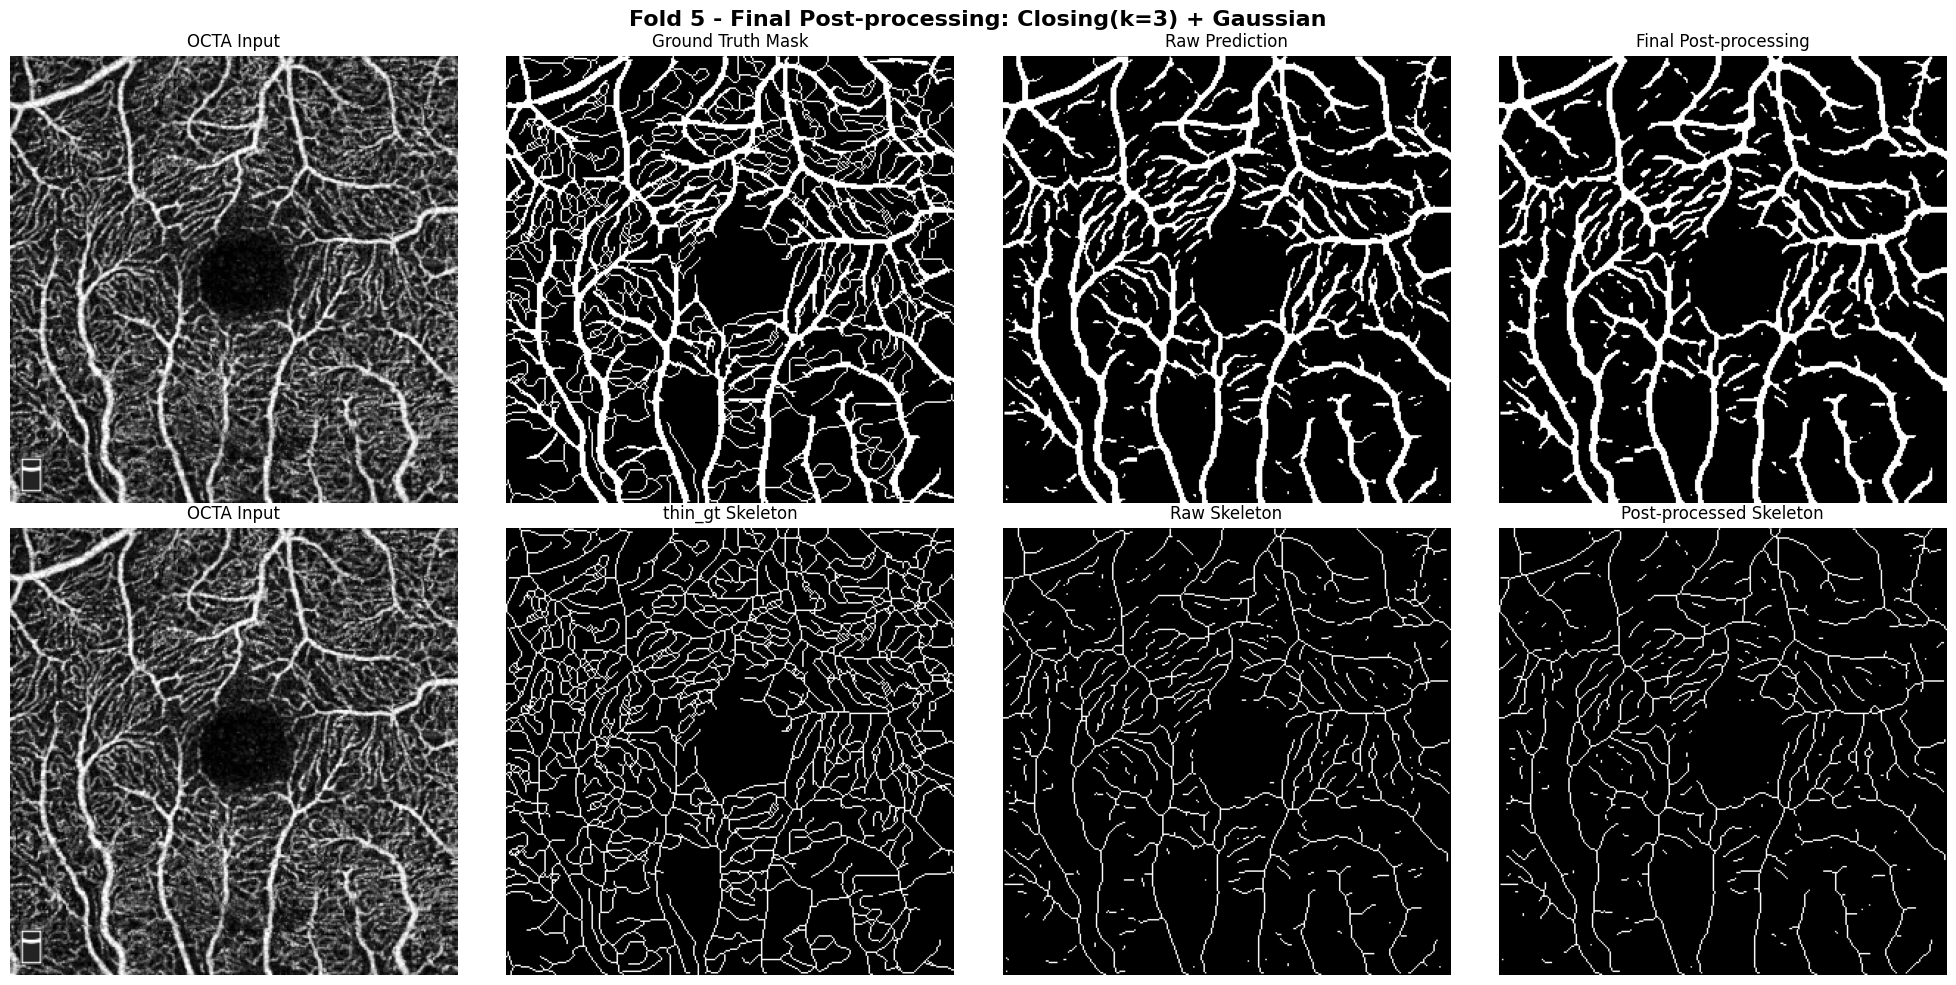

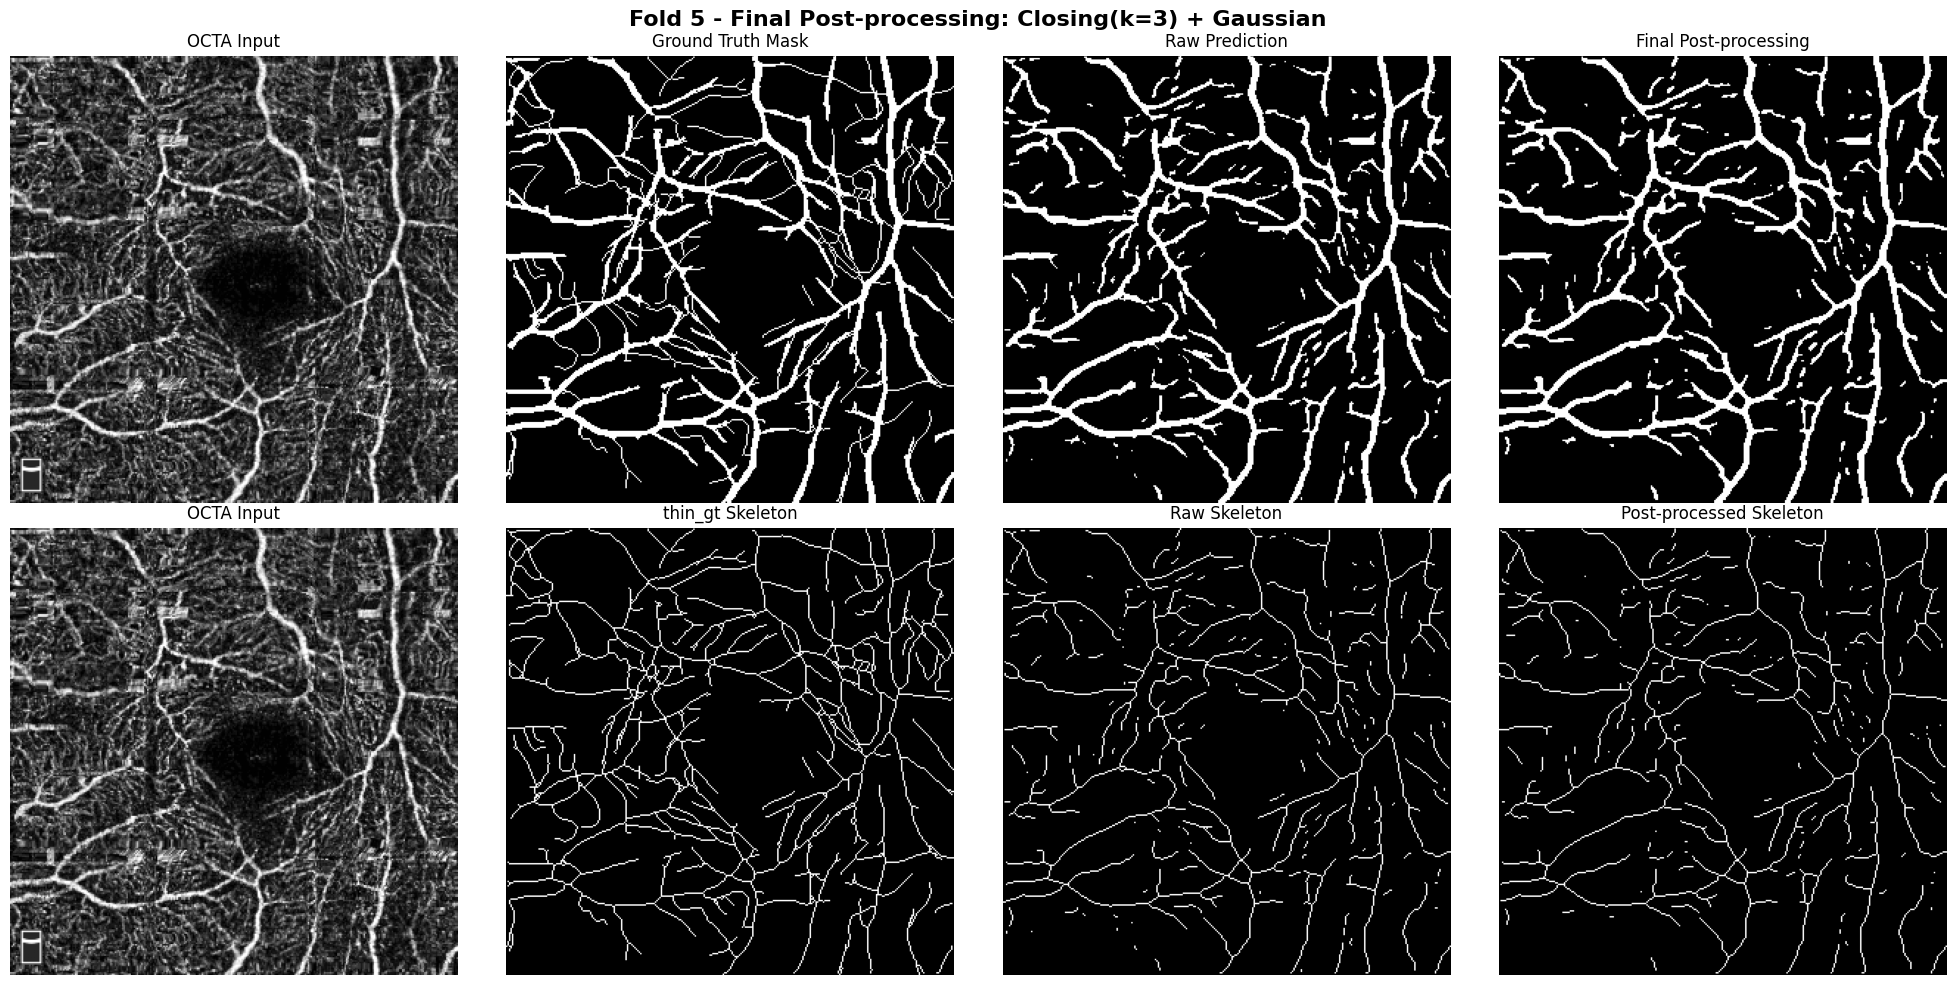

In [12]:
# ============================================================
# VISUALIZZAZIONE FINALE:
# GT vs RAW vs POST-PROCESSING
# THIN GT vs RAW SKELETON vs PP SKELETON
# ============================================================

print("\n🔍 Generazione visualizzazione configurazione finale...")


# -----------------------------
# Configurazione scelta
# -----------------------------

final_cfg_dict = next(
    cfg for cfg in configs
    if cfg['name'] == final_config.name
)


print("Configurazione visualizzata:")
print(final_cfg_dict)



# -----------------------------
# Scegli fold da visualizzare
# -----------------------------

VIS_FOLD = 4   # Fold 5 (0-indexed)


fold_splits = list(
    skf.split(df_rose.index, df_rose['class'])
)

_, val_idx = fold_splits[VIS_FOLD]


df_vis = df_rose.iloc[val_idx].reset_index(drop=True)



# -----------------------------
# Carica modello
# -----------------------------

model_vis = get_attention_unet().to(DEVICE)

model_vis.load_state_dict(
    torch.load(
        f"/kaggle/input/datasets/liviapantarotto/models-rose/final_models_rose/final_model_ROSE_fold{fold+1}.pth",
        weights_only=True
    )
)

model_vis.eval()



# -----------------------------
# Dataset validation
# -----------------------------

dataset_vis = SegmentationDataset(
    df_vis['image_path'].tolist(),
    df_vis['mask_path'].tolist(),
    val_transform
)


loader_vis = DataLoader(
    dataset_vis,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)


# -----------------------------
# Predizione
# -----------------------------

images, masks = next(iter(loader_vis))

images = images.to(DEVICE)
masks = masks.to(DEVICE)


with torch.no_grad():

    outputs = model_vis(images)

    preds = (
        torch.sigmoid(outputs) > 0.5
    ).float().cpu().numpy()



imgs_np = images.cpu().numpy()
gt_np = masks.cpu().numpy()



# -----------------------------
# Visualizzazione
# -----------------------------

for i in range(preds.shape[0]):

    img = imgs_np[i,0]

    gt = gt_np[i,0]

    raw_pred = preds[i,0]



    # =========================
    # Post-processing volumetrico
    # =========================

    pp_pred = apply_postprocessing_advanced(
        raw_pred,
        morph_op=final_cfg_dict['morph_op'],
        kernel_size=final_cfg_dict['kernel_size'],
        smooth=final_cfg_dict['smooth'],
        min_area=final_cfg_dict['min_area'],
        do_skeleton=False
    )



    # =========================
    # Skeleton extraction
    # =========================

    thin_gt_skeleton = skeletonize(
        gt > 0.5
    )


    raw_skeleton = apply_topological_postprocessing(
        raw_pred,
        morph_op=None,
        kernel_size=3,
        smooth=None,
        min_area=0
    )


    pp_skeleton = apply_topological_postprocessing(
        raw_pred,
        morph_op=final_cfg_dict['morph_op'],
        kernel_size=final_cfg_dict['kernel_size'],
        smooth=final_cfg_dict['smooth'],
        min_area=final_cfg_dict['min_area']
    )



    # =========================
    # Plot
    # =========================

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(20,10)
    )


    fig.suptitle(
        f"Fold {VIS_FOLD+1} - Final Post-processing: {final_config.name}",
        fontsize=16,
        weight="bold"
    )


    # -------------------------
    # Riga 1: segmentation
    # -------------------------

    axes[0,0].imshow(
        img,
        cmap="gray"
    )
    axes[0,0].set_title(
        "OCTA Input"
    )


    axes[0,1].imshow(
        gt,
        cmap="gray"
    )
    axes[0,1].set_title(
        "Ground Truth Mask"
    )


    axes[0,2].imshow(
        raw_pred,
        cmap="gray"
    )
    axes[0,2].set_title(
        "Raw Prediction"
    )


    axes[0,3].imshow(
        pp_pred,
        cmap="gray"
    )
    axes[0,3].set_title(
        "Final Post-processing"
    )



    # -------------------------
    # Riga 2: skeleton
    # -------------------------

    axes[1,0].imshow(
        img,
        cmap="gray"
    )
    axes[1,0].set_title(
        "OCTA Input"
    )


    axes[1,1].imshow(
        thin_gt_skeleton,
        cmap="gray"
    )
    axes[1,1].set_title(
        "thin_gt Skeleton"
    )


    axes[1,2].imshow(
        raw_skeleton,
        cmap="gray"
    )
    axes[1,2].set_title(
        "Raw Skeleton"
    )


    axes[1,3].imshow(
        pp_skeleton,
        cmap="gray"
    )
    axes[1,3].set_title(
        "Post-processed Skeleton"
    )



    for ax in axes.ravel():
        ax.axis("off")


    plt.tight_layout()
    plt.show()



del model_vis
torch.cuda.empty_cache()


🚀 FASE 3: INFERENZA TEST SET UFFICIALE (ENSEMBLE 5 FOLD)
✅ Test immagini trovate: 18
Caricamento modello Fold 0/5
Caricamento modello Fold 1/5
Caricamento modello Fold 2/5
Caricamento modello Fold 3/5
Caricamento modello Fold 4/5
✅ Ensemble 5-fold caricato
Single forward time: 0.0181 s/image

🚀 Avvio inferenza Ensemble + TTA...

✅ Inferenza completata
Maschere salvate in: /kaggle/working/test_predictions
Scheletri salvati in: /kaggle/working/test_skeletons

🏆 RISULTATI FINALI - TEST SET INDIPENDENTE ROSE-1

--- TOTAL ---
Dice:      0.7358 ± 0.0558
clDice:    0.6431 ± 0.1048
AUC:       0.9231 ± 0.0407
Accuracy:  0.9073 ± 0.0295
G-mean:    0.8116 ± 0.0542
Kappa:     0.6802 ± 0.0729
FDR:       0.2035 ± 0.0317
Time/img:  0.1497 s

--- SVC ---
Dice:      0.7618 ± 0.0496
clDice:    0.6739 ± 0.1027
AUC:       0.9373 ± 0.0348
Accuracy:  0.9153 ± 0.0275
G-mean:    0.8335 ± 0.0504
Kappa:     0.7106 ± 0.0660
FDR:       0.1919 ± 0.0242
Time/img:  0.1486 s

--- FULL ---
Dice:      0.7097 ± 0.0491


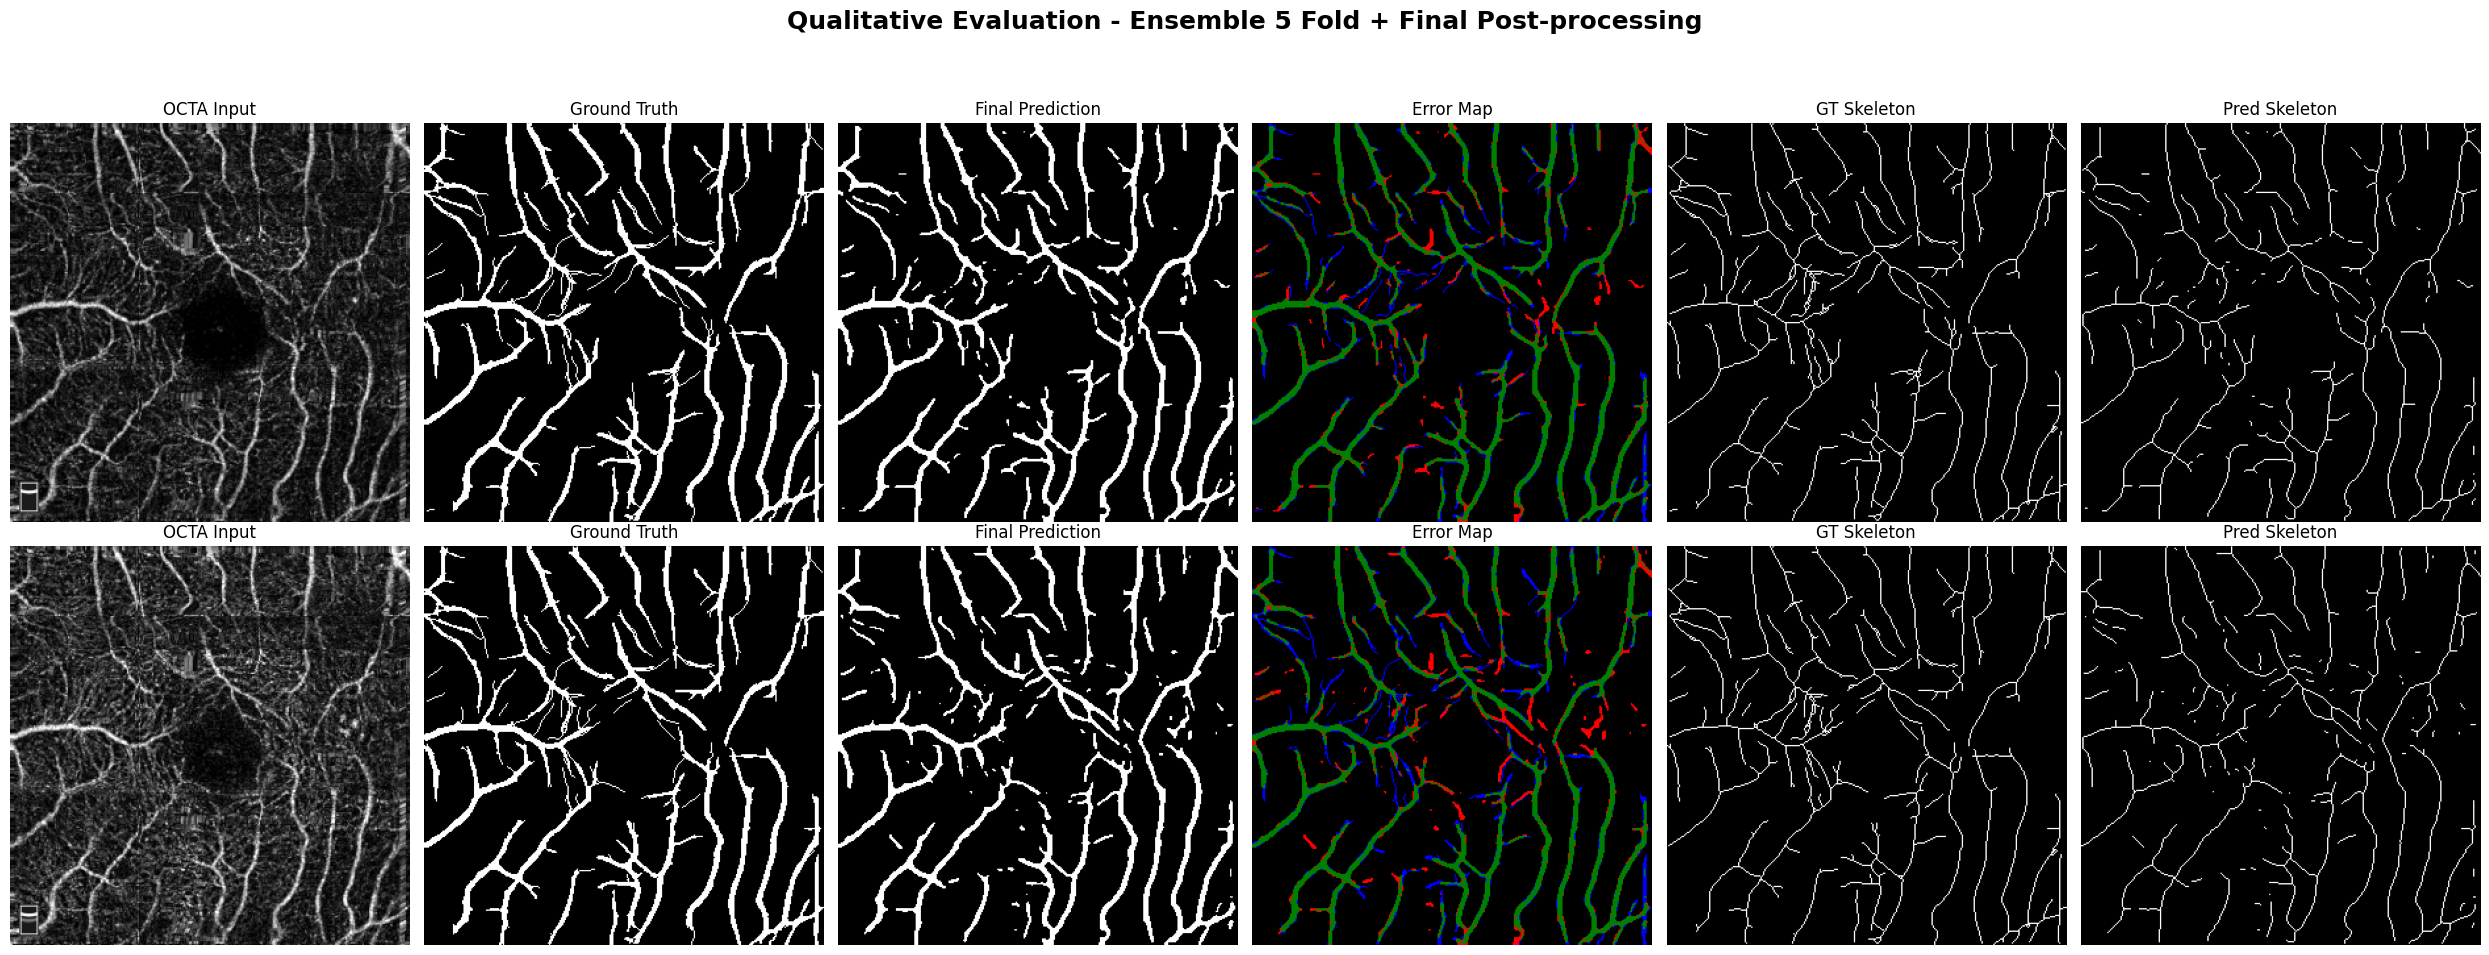


✅ Inferenza completa.


In [13]:
# =====================================================================
# INFERENZA UFFICIALE SU TEST SET E CALCOLO METRICHE ESTESE
# ENSEMBLE 5-FOLD + TTA + FINAL POST-PROCESSING
# =====================================================================

print("\n" + "="*60)
print("🚀 FASE 3: INFERENZA TEST SET UFFICIALE (ENSEMBLE 5 FOLD)")
print("="*60)



# ============================================================
# 1. FUNZIONE METRICHE ESTESE
# ============================================================

def calculate_extended_metrics(gt_mask, pred_mask, pred_probs=None):

    y_true = gt_mask.flatten().astype(int)
    y_pred = pred_mask.flatten().astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0,1]
    ).ravel()


    acc = (tp + tn) / (tp + tn + fp + fn + 1e-7)

    sens = tp / (tp + fn + 1e-7)

    spec = tn / (tn + fp + 1e-7)

    g_mean = np.sqrt(sens * spec)

    fdr = fp / (tp + fp + 1e-7)

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )


    try:

        if pred_probs is not None:
            auc = roc_auc_score(
                y_true,
                pred_probs.flatten()
            )

        else:
            auc = roc_auc_score(
                y_true,
                y_pred
            )

    except ValueError:

        auc = 0.5


    return acc, auc, g_mean, kappa, fdr



# ============================================================
# 2. CARICAMENTO TEST SET
# ============================================================

test_image_paths = []
test_mask_paths = []
test_classes = []


DIR_TEST_SVC_IMG = "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/test/img"
DIR_TEST_SVC_GT  = "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/test/gt"


DIR_TEST_FULL_IMG = "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/test/img"
DIR_TEST_FULL_GT  = "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/test/gt"



def append_test_data(img_dir, gt_dir, class_name):

    img_list = sorted(
        glob(os.path.join(img_dir,"*"))
    )

    gt_list = sorted(
        glob(os.path.join(gt_dir,"*"))
    )


    for img_p, gt_p in zip(img_list, gt_list):

        test_image_paths.append(img_p)

        test_mask_paths.append(gt_p)

        test_classes.append(class_name)



append_test_data(
    DIR_TEST_SVC_IMG,
    DIR_TEST_SVC_GT,
    "SVC"
)


append_test_data(
    DIR_TEST_FULL_IMG,
    DIR_TEST_FULL_GT,
    "Full"
)


print(
    f"✅ Test immagini trovate: {len(test_image_paths)}"
)



test_dataset = SegmentationDataset(
    test_image_paths,
    test_mask_paths,
    val_transform
)


test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)



# ============================================================
# 3. CARICAMENTO ENSEMBLE 5 FOLD
# ============================================================

models = []


for fold in range(5):

    print(
        f"Caricamento modello Fold {fold}/5"
    )


    model = get_attention_unet().to(DEVICE)


    model.load_state_dict(
        torch.load(
            f"/kaggle/input/datasets/liviapantarotto/models-rose/final_models_rose/final_model_ROSE_fold{fold+1}.pth",
            map_location=DEVICE,
            weights_only=True
        )
    )


    model.eval()


    models.append(model)



print("✅ Ensemble 5-fold caricato")

# ============================================================
# SINGLE FORWARD PASS INFERENCE TIME (304x304)
# Comparable with OCTA-Net timing
# ============================================================

import time

# utilizziamo un solo modello dell'ensemble
benchmark_model = models[0]
benchmark_model.eval()

# prendiamo una singola immagine dal test loader
images, _ = next(iter(test_loader))
images = images.to(DEVICE)

# warm-up GPU
with torch.no_grad():
    for _ in range(10):
        _ = benchmark_model(images)

# sincronizzazione GPU prima del timing
torch.cuda.synchronize()

# timing di una singola forward pass
start_time = time.time()

with torch.no_grad():
    _ = benchmark_model(images)

# sincronizzazione GPU dopo il timing
torch.cuda.synchronize()

end_time = time.time()

single_forward_time = end_time - start_time

print(
    f"Single forward time: {single_forward_time:.4f} s/image"
)

# ============================================================
# 4. CARTELLE OUTPUT
# ============================================================

OUTPUT_DIR = "/kaggle/working/test_predictions"

SKELETON_DIR = "/kaggle/working/test_skeletons"


os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

os.makedirs(
    SKELETON_DIR,
    exist_ok=True
)



# ============================================================
# 5. STORAGE RISULTATI
# ============================================================

test_results = {

    'SVC': {
        'dice':[],
        'cldice':[],
        'acc':[],
        'auc':[],
        'g_mean':[],
        'kappa':[],
        'fdr':[],
        'time':[]
    },


    'Full': {
        'dice':[],
        'cldice':[],
        'acc':[],
        'auc':[],
        'g_mean':[],
        'kappa':[],
        'fdr':[],
        'time':[]
    },


    'Total': {
        'dice':[],
        'cldice':[],
        'acc':[],
        'auc':[],
        'g_mean':[],
        'kappa':[],
        'fdr':[],
        'time':[]
    }

}



# ============================================================
# 6. INFERENZA ENSEMBLE + TTA
# ============================================================

print("\n🚀 Avvio inferenza Ensemble + TTA...")


with torch.no_grad():


    for i,(images,masks) in enumerate(test_loader):


        images = images.to(DEVICE)

        masks = masks.to(DEVICE)



        gt_mask = masks.cpu().numpy()[0,0]


        current_class = test_classes[i]


        filename = os.path.basename(
            test_image_paths[i]
        )



        start_time = time.time()



        # ----------------------------------------
        # Predizione 5 fold + TTA
        # ----------------------------------------

        fold_predictions = []


        for model in models:


            pred1 = torch.sigmoid(
                model(images)
            )


            pred2 = torch.flip(
                torch.sigmoid(
                    model(
                        torch.flip(images,[3])
                    )
                ),
                [3]
            )


            pred3 = torch.flip(
                torch.sigmoid(
                    model(
                        torch.flip(images,[2])
                    )
                ),
                [2]
            )


            pred_tta = (
                pred1 +
                pred2 +
                pred3
            ) / 3.0


            fold_predictions.append(
                pred_tta
            )



        # media ensemble 5 fold

        pred_probs = torch.stack(
            fold_predictions
        ).mean(dim=0)



        pred_probs_np = (
            pred_probs.cpu()
            .numpy()[0,0]
        )



        # threshold finale

        pred_bin_raw = (
            pred_probs_np > 0.5
        ).astype(np.float32)



        inf_time = time.time() - start_time



        # ----------------------------------------
        # FINAL POST PROCESSING
        # Closing(k=3)+Gaussian
        # ----------------------------------------

        pred_final = apply_postprocessing_advanced(
            pred_bin_raw,
            morph_op='closing',
            kernel_size=3,
            smooth='gaussian',
            min_area=0,
            do_skeleton=False
        )



        # ----------------------------------------
        # Skeleton finale per biomarcatori
        # ----------------------------------------

        final_skeleton = skeletonize(
            pred_final > 0.5
        )


        cv2.imwrite(
            os.path.join(
                SKELETON_DIR,
                f"{current_class}_{filename}"
            ),
            (final_skeleton*255).astype(np.uint8)
        )



        # salva maschera finale

        cv2.imwrite(
            os.path.join(
                OUTPUT_DIR,
                f"{current_class}_{filename}"
            ),
            (pred_final*255).astype(np.uint8)
        )



        # ----------------------------------------
        # Metriche
        # ----------------------------------------

        inter = np.sum(
            pred_final * gt_mask
        )


        dice = (
            2*inter + 1e-7
        ) / (
            np.sum(pred_final)
            +
            np.sum(gt_mask)
            +
            1e-7
        )


        cldice = calculate_cldice(
            pred_final,
            gt_mask
        )


        acc, auc, g_mean, kappa, fdr = calculate_extended_metrics(
            gt_mask,
            pred_final,
            pred_probs_np
        )



        for category in [
            current_class,
            'Total'
        ]:

            test_results[category]['dice'].append(dice)

            test_results[category]['cldice'].append(cldice)

            test_results[category]['acc'].append(acc)

            test_results[category]['auc'].append(auc)

            test_results[category]['g_mean'].append(g_mean)

            test_results[category]['kappa'].append(kappa)

            test_results[category]['fdr'].append(fdr)

            test_results[category]['time'].append(inf_time)



print(
    "\n✅ Inferenza completata"
)

print(
    f"Maschere salvate in: {OUTPUT_DIR}"
)

print(
    f"Scheletri salvati in: {SKELETON_DIR}"
)

# =====================================================================
# 7. RISULTATI FINALI TEST SET
# =====================================================================

print("\n" + "="*80)
print("🏆 RISULTATI FINALI - TEST SET INDIPENDENTE ROSE-1")
print("="*80)


categories = [
    'Total',
    'SVC',
    'Full'
]


for cat in categories:

    print(
        f"\n--- {cat.upper()} ---"
    )


    print(
        f"Dice:      "
        f"{np.mean(test_results[cat]['dice']):.4f} "
        f"± {np.std(test_results[cat]['dice']):.4f}"
    )


    print(
        f"clDice:    "
        f"{np.mean(test_results[cat]['cldice']):.4f} "
        f"± {np.std(test_results[cat]['cldice']):.4f}"
    )


    print(
        f"AUC:       "
        f"{np.mean(test_results[cat]['auc']):.4f} "
        f"± {np.std(test_results[cat]['auc']):.4f}"
    )


    print(
        f"Accuracy:  "
        f"{np.mean(test_results[cat]['acc']):.4f} "
        f"± {np.std(test_results[cat]['acc']):.4f}"
    )


    print(
        f"G-mean:    "
        f"{np.mean(test_results[cat]['g_mean']):.4f} "
        f"± {np.std(test_results[cat]['g_mean']):.4f}"
    )


    print(
        f"Kappa:     "
        f"{np.mean(test_results[cat]['kappa']):.4f} "
        f"± {np.std(test_results[cat]['kappa']):.4f}"
    )


    print(
        f"FDR:       "
        f"{np.mean(test_results[cat]['fdr']):.4f} "
        f"± {np.std(test_results[cat]['fdr']):.4f}"
    )


    print(
        f"Time/img:  "
        f"{np.mean(test_results[cat]['time']):.4f} s"
    )


print("\n" + "="*80)



# =====================================================================
# 8. VISUALIZZAZIONE QUALITATIVA TEST SET
# =====================================================================

print("\n🎨 Generazione visualizzazione qualitativa...")


# scegli un esempio SVC e uno Full

idx_svc = next(
    (
        i for i,c in enumerate(test_classes)
        if c == "SVC"
    ),
    None
)


idx_full = next(
    (
        i for i,c in enumerate(test_classes)
        if c == "Full"
    ),
    None
)



sample_indices = [
    i for i in [
        idx_svc,
        idx_full
    ]
    if i is not None
]



num_samples = len(sample_indices)



if num_samples > 0:


    fig, axes = plt.subplots(
        num_samples,
        6,
        figsize=(25,5*num_samples)
    )


    fig.suptitle(
        "Qualitative Evaluation - Ensemble 5 Fold + Final Post-processing",
        fontsize=18,
        weight="bold"
    )



    if num_samples == 1:

        axes = axes.reshape(1,-1)



    import matplotlib.colors as mcolors


    cmap_error = mcolors.ListedColormap(
        [
            'black',
            'blue',
            'red',
            'green'
        ]
    )


    bounds = [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5
    ]


    norm = mcolors.BoundaryNorm(
        bounds,
        cmap_error.N
    )



    for row,idx in enumerate(sample_indices):


        img_path = test_image_paths[idx]

        gt_path = test_mask_paths[idx]


        current_class = test_classes[idx]

        filename = os.path.basename(
            img_path
        )



        pred_path = os.path.join(
            OUTPUT_DIR,
            f"{current_class}_{filename}"
        )


        skeleton_path = os.path.join(
            SKELETON_DIR,
            f"{current_class}_{filename}"
        )



        # immagini

        img = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )


        gt_mask = (
            cv2.imread(
                gt_path,
                cv2.IMREAD_GRAYSCALE
            )
            >127
        ).astype(np.uint8)



        pred_mask = (
            cv2.imread(
                pred_path,
                cv2.IMREAD_GRAYSCALE
            )
            >127
        ).astype(np.uint8)



        pred_skeleton = (
            cv2.imread(
                skeleton_path,
                cv2.IMREAD_GRAYSCALE
            )
            >127
        ).astype(np.uint8)



        gt_skeleton = skeletonize(
            gt_mask>0
        )



        # error map

        error_map = np.zeros_like(
            gt_mask,
            dtype=np.uint8
        )


        # TP

        error_map[
            (gt_mask==1)&
            (pred_mask==1)
        ] = 3


        # FP

        error_map[
            (gt_mask==0)&
            (pred_mask==1)
        ] = 2


        # FN

        error_map[
            (gt_mask==1)&
            (pred_mask==0)
        ] = 1



        # --------------------------
        # Plot
        # --------------------------


        panels = [

            (img,"OCTA Input","gray"),

            (gt_mask,"Ground Truth","gray"),

            (pred_mask,"Final Prediction","gray"),

            (error_map,"Error Map","error"),

            (gt_skeleton,"GT Skeleton","gray"),

            (pred_skeleton,"Pred Skeleton","gray")

        ]



        for col,(data,title,cmap) in enumerate(panels):


            ax = axes[row,col]


            if cmap=="error":

                ax.imshow(
                    data,
                    cmap=cmap_error,
                    norm=norm
                )

            else:

                ax.imshow(
                    data,
                    cmap="gray"
                )


            ax.set_title(
                title,
                fontsize=12
            )


            ax.axis("off")



    plt.tight_layout(
        rect=[0,0,1,0.95]
    )


    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "qualitative_test_results.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()



else:

    print(
        "⚠️ Nessuna immagine trovata per visualizzazione"
    )



# =====================================================================
# 9. PULIZIA GPU
# =====================================================================

del models

gc.collect()

torch.cuda.empty_cache()


print("\n✅ Inferenza completa.")

In [ ]:
# ==========================================================
# SAVE QUALITATIVE PANELS FOR MULTIPLE TEST IMAGES
# ==========================================================

# scegli quali immagini salvare
selected_indices = [
    i for i,c in enumerate(test_classes)
    if c == "SVC"
]


BASE_DIR = os.path.join(
    OUTPUT_DIR,
    "qualitative_panels"
)

os.makedirs(
    BASE_DIR,
    exist_ok=True
)


for idx in selected_indices:


    img_path = test_image_paths[idx]
    gt_path = test_mask_paths[idx]

    current_class = test_classes[idx]

    filename = os.path.splitext(
        os.path.basename(img_path)
    )[0]


    pred_path = os.path.join(
        OUTPUT_DIR,
        f"{current_class}_{os.path.basename(img_path)}"
    )


    skeleton_path = os.path.join(
        SKELETON_DIR,
        f"{current_class}_{os.path.basename(img_path)}"
    )


    # -------------------------
    # Load
    # -------------------------

    img = cv2.imread(
        img_path,
        cv2.IMREAD_GRAYSCALE
    )


    gt_mask = (
        cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)>127
    ).astype(np.uint8)


    pred_mask = (
        cv2.imread(pred_path, cv2.IMREAD_GRAYSCALE)>127
    ).astype(np.uint8)


    pred_skeleton = (
        cv2.imread(
            skeleton_path,
            cv2.IMREAD_GRAYSCALE
        )>127
    )


    gt_skeleton = skeletonize(
        gt_mask>0
    )


    # -------------------------
    # Skeleton overlap
    # -------------------------

    overlap_rgb = np.zeros(
        (
            gt_skeleton.shape[0],
            gt_skeleton.shape[1],
            3
        ),
        dtype=np.uint8
    )


    overlap_rgb[gt_skeleton > 0] = [255,0,0]

    overlap_rgb[pred_skeleton > 0] = [0,255,0]

    overlap_rgb[
        (gt_skeleton > 0) &
        (pred_skeleton > 0)
    ] = [255,255,0]


    # -------------------------
    # Save folder
    # -------------------------

    save_dir = os.path.join(
        BASE_DIR,
        filename
    )

    os.makedirs(
        save_dir,
        exist_ok=True
    )


    panels = {

        "octa_input": (img,"gray"),

        "ground_truth": (gt_mask,"gray"),

        "prediction": (pred_mask,"gray"),

        "skeleton_overlap": (overlap_rgb,None)

    }


    # -------------------------
    # Save each panel
    # -------------------------

    for name,(data,cmap) in panels.items():

        fig = plt.figure(
            figsize=(3,3)
        )

        ax = fig.add_axes(
            [0,0,1,1]
        )


        if cmap is None:

            ax.imshow(
                data,
                interpolation="nearest"
            )

        else:

            ax.imshow(
                data,
                cmap=cmap,
                interpolation="nearest"
            )


        ax.axis("off")


        fig.savefig(
            os.path.join(
                save_dir,
                f"{name}.png"
            ),
            dpi=600,
            bbox_inches="tight",
            pad_inches=0
        )


        plt.close(fig)


    print(
        f"✅ Salvata: {filename}"
    )


✅ Salvata: 01
✅ Salvata: 02
✅ Salvata: 03
✅ Salvata: 04
✅ Salvata: 05
✅ Salvata: 06
✅ Salvata: 07
✅ Salvata: 08
✅ Salvata: 09
0 01.tif SVC
1 02.tif SVC
2 03.tif SVC
3 04.tif SVC
4 05.tif SVC
5 06.tif SVC
6 07.tif SVC
7 08.tif SVC
8 09.tif SVC
9 01.png Full
10 02.png Full
11 03.png Full
12 04.png Full
13 05.png Full
14 06.png Full
15 07.png Full
16 08.png Full
17 09.png Full



🩸 FASE 4: ESTRAZIONE BIOMARCATORI, STRATIFICAZIONE E SALVATAGGIO
📂 I grafici e i dati verranno salvati in alta risoluzione in: /kaggle/working/phase4_results
⏳ Estrazione incrociata dei 4 biomarcatori da 19 immagini...
      Filename Category      Dice    clDice     VD_GT   VD_Pred  VD_Error_%  \
0  Full_01.png     Full  0.803961  0.788938  0.142605  0.137130    3.839439   
1  Full_02.png     Full  0.706284  0.612085  0.152560  0.132769   12.972543   
2  Full_03.png     Full  0.747839  0.662133  0.177686  0.162775    8.391689   
3  Full_04.png     Full  0.726997  0.673684  0.192889  0.163554   15.208115   
4  Full_05.png     Full  0.747983  0.687257  0.133840  0.122360    8.577890   

    SL_GT  SL_Pred  SL_Error_%     FD_GT   FD_Pred  FD_Error_%   TORT_GT  \
0  3544.0   3327.0    6.123025  1.984283  1.984074    0.010534  1.114237   
1  6127.0   3135.0   48.833034  1.987098  1.983445    0.183828  1.264014   
2  7306.0   4018.0   45.004106  1.995170  1.994076    0.054835  1.160258   
3

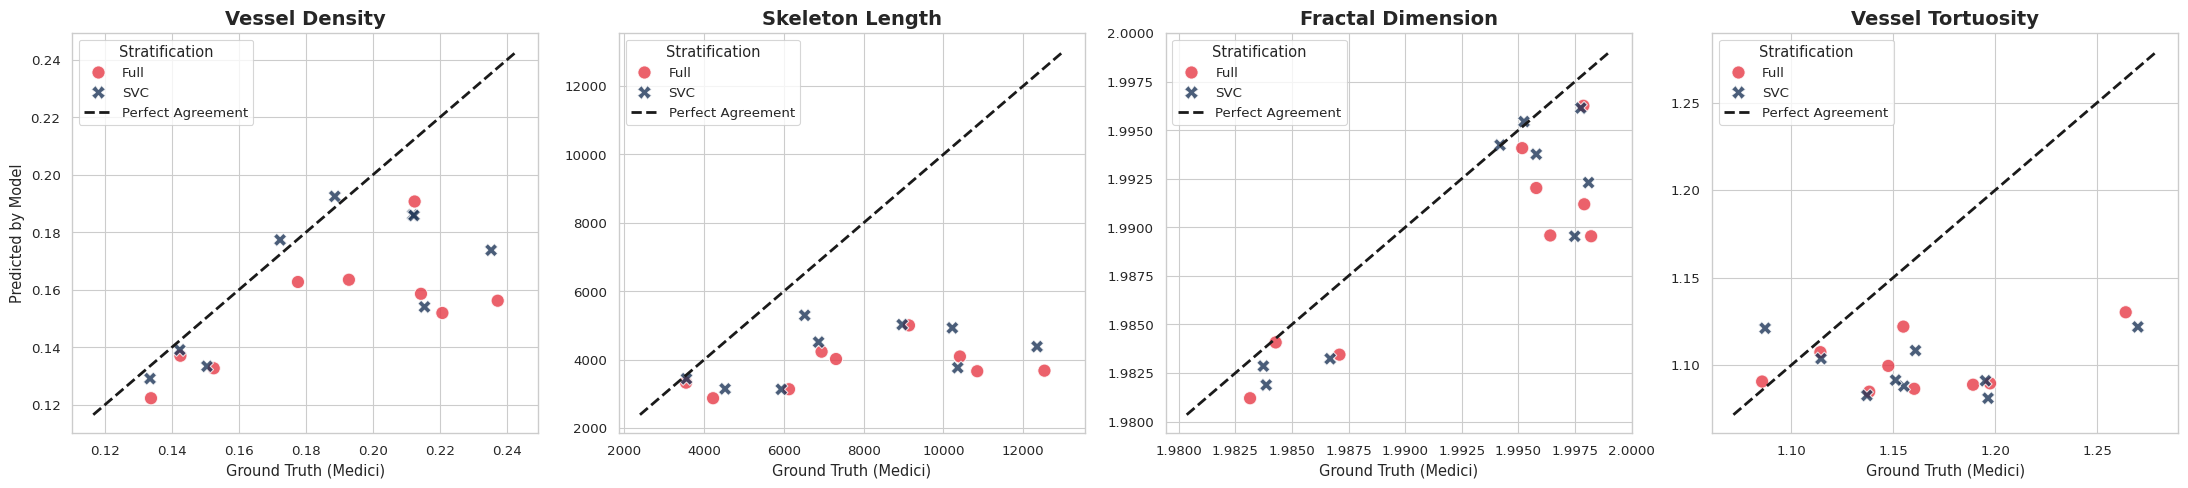

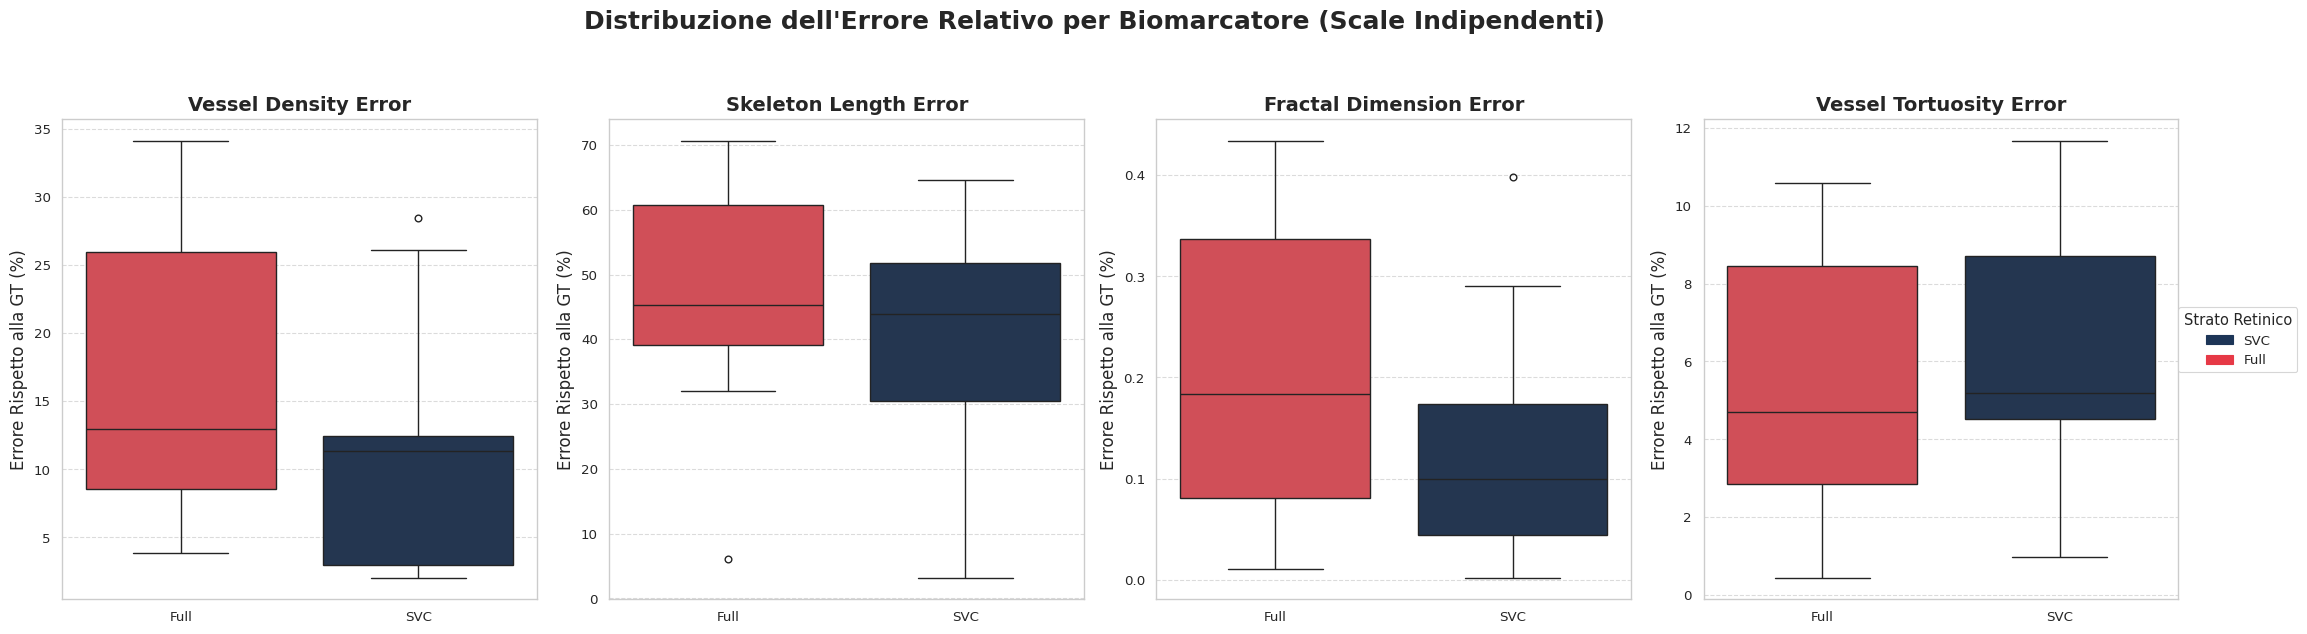


📈 Relationship between Dice and biomarker estimation error...


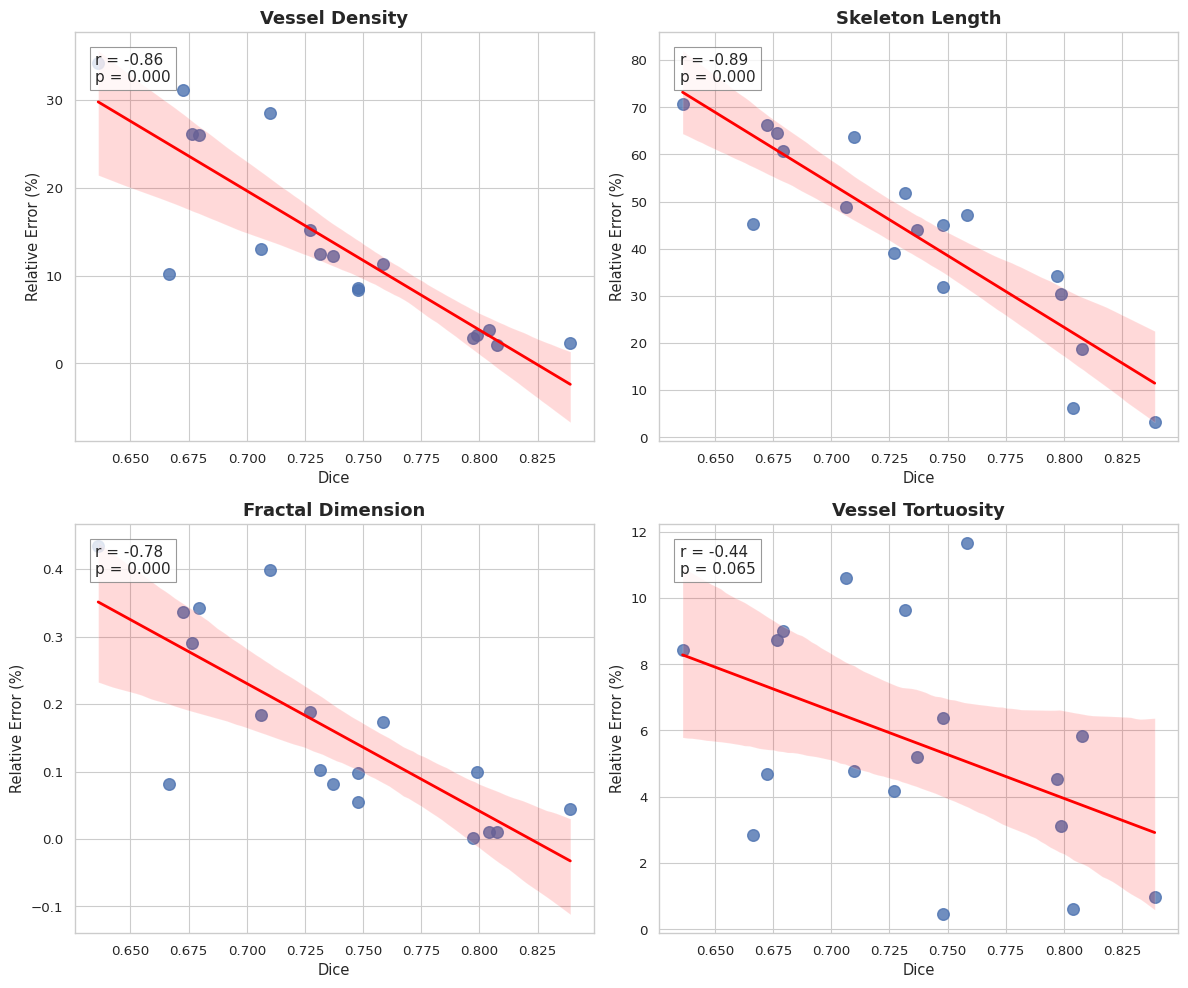


📈 Relationship between clDice and biomarker estimation error...


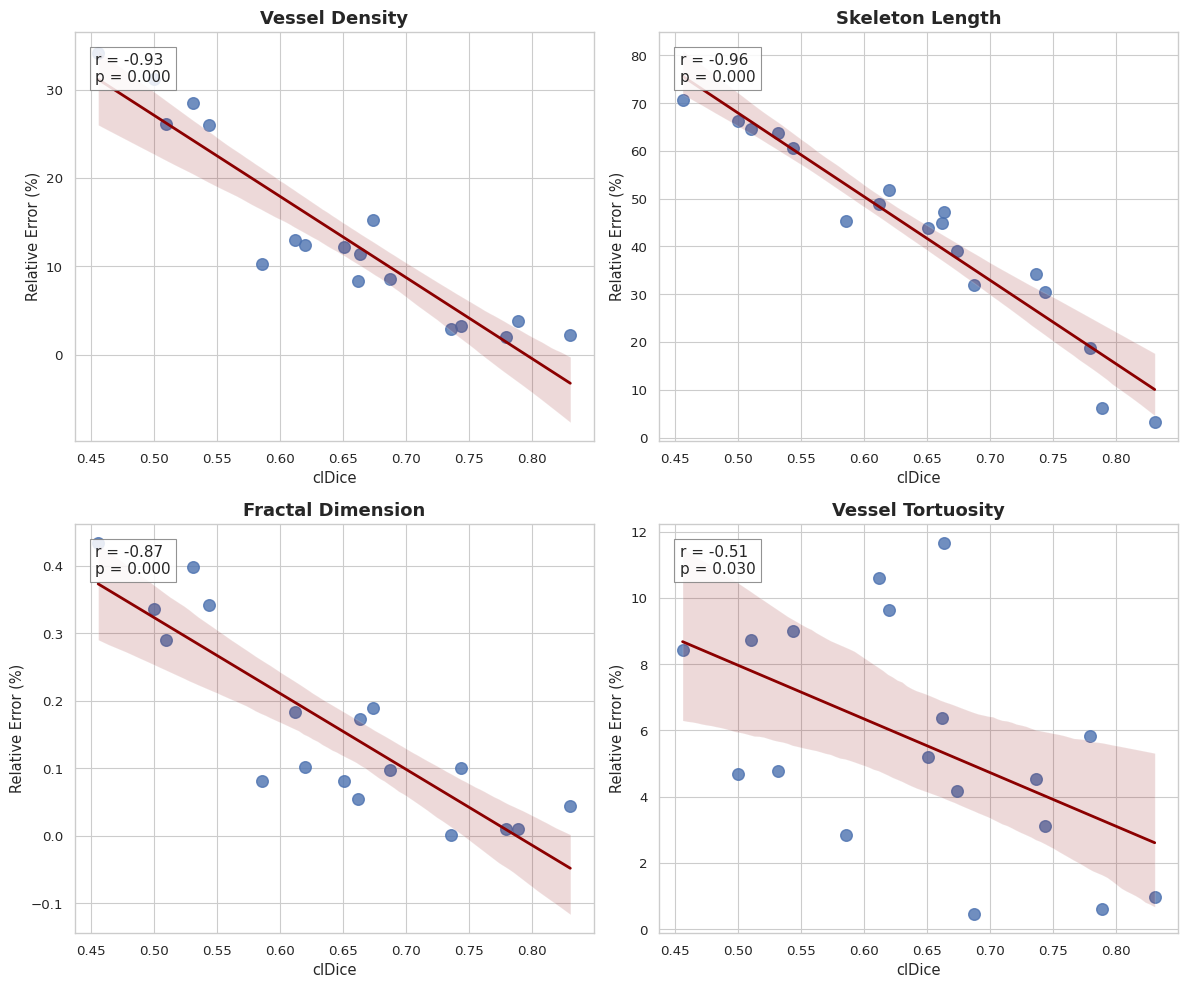


⚖️ Generazione Bland-Altman Plots...


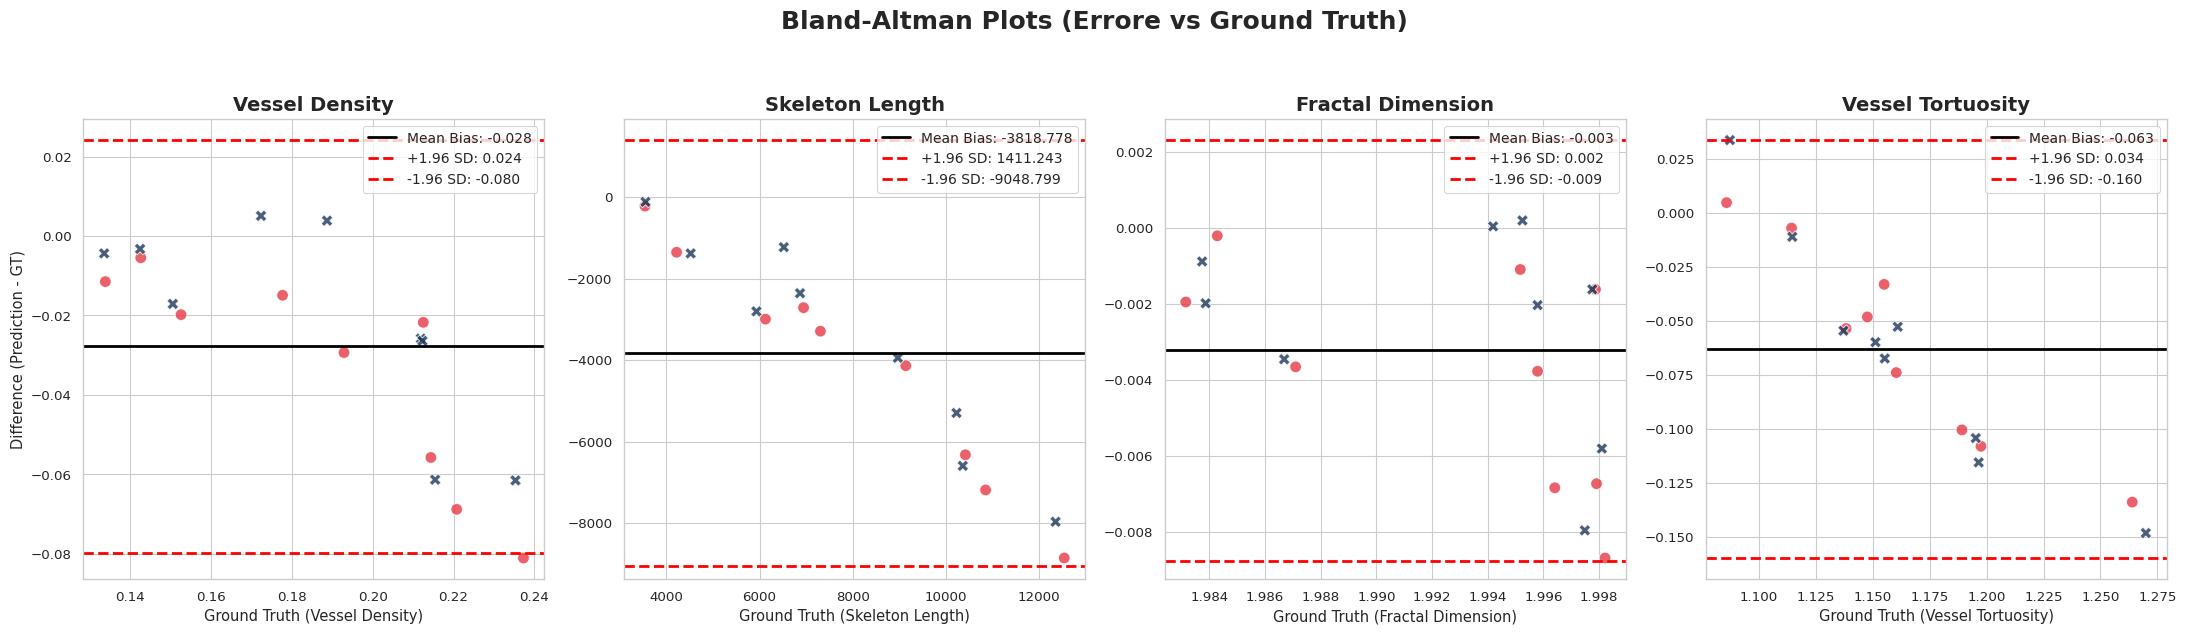


🖼️ Generazione e salvataggio del Pannello Qualitativo (Skeleton & Overlap)...


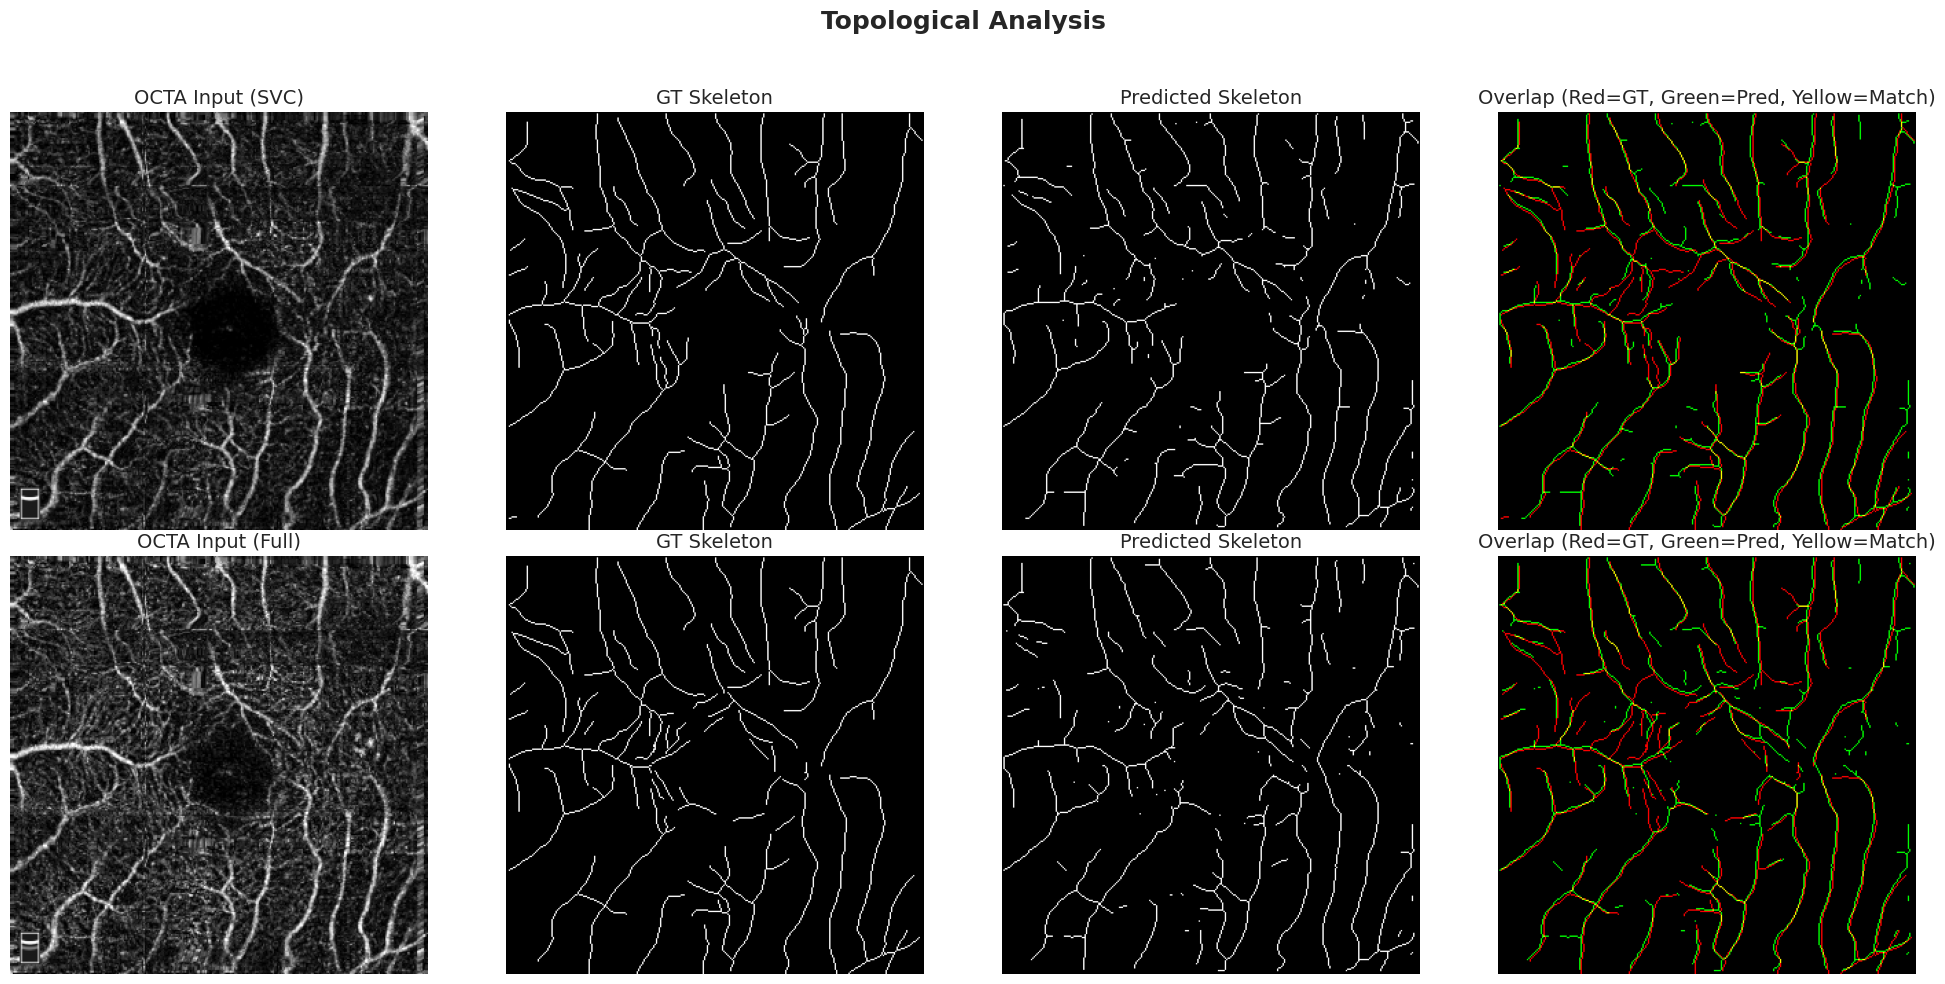


🎉 Finito! Tutti i file pronti per la pubblicazione sono in: /kaggle/working/phase4_results

CORRELATION ANALYSIS
           Biomarker  Pearson Dice  Pearson Dice p  Pearson clDice  \
0     Vessel Density     -0.858394    5.162981e-06       -0.933637   
1    Skeleton Length     -0.890535    7.315229e-07       -0.962283   
2  Fractal Dimension     -0.777149    1.478428e-04       -0.867162   
3  Vessel Tortuosity     -0.443343    6.536106e-02       -0.510305   

   Pearson clDice p  Spearman Dice  Spearman Dice p  Spearman clDice  \
0      1.534002e-08      -0.867905         0.000003        -0.905057   
1      1.829103e-10      -0.876161         0.000002        -0.971104   
2      3.186952e-06      -0.746130         0.000377        -0.801858   
3      3.048127e-02      -0.345717         0.159953        -0.498452   

   Spearman clDice p  
0       2.455886e-07  
1       2.232220e-11  
2       6.280600e-05  
3       3.525364e-02  

Saved: /kaggle/working/phase4_results/biomarker_correlatio

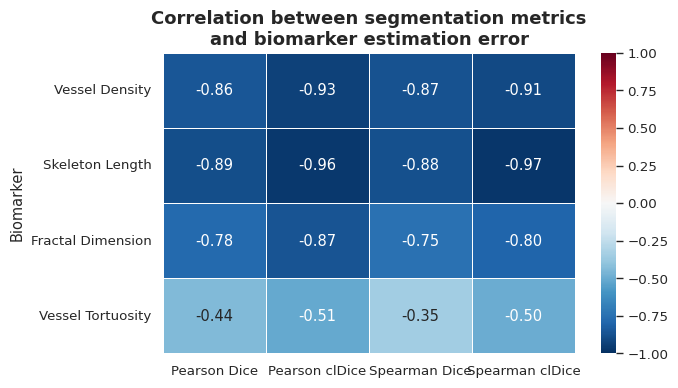



IMPROVEMENT OF clDice OVER DICE
           Biomarker  |Pearson Dice|  |Pearson clDice|  Difference
2  Fractal Dimension        0.777149          0.867162    0.090013
0     Vessel Density        0.858394          0.933637    0.075243
1    Skeleton Length        0.890535          0.962283    0.071749
3  Vessel Tortuosity        0.443343          0.510305    0.066961


In [15]:
#FASE FINALE ANALISI BIOMARCATORI

import numpy as np
from scipy.ndimage import convolve
from skimage.measure import label, regionprops
from scipy.stats import pearsonr
import seaborn as sns


print("\n" + "="*80)
print("🩸 FASE 4: ESTRAZIONE BIOMARCATORI, STRATIFICAZIONE E SALVATAGGIO")
print("="*80)

# ==========================================
# CREAZIONE CARTELLA DI OUTPUT PER I RISULTATI
# ==========================================
RESULTS_DIR = "/kaggle/working/phase4_results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"📂 I grafici e i dati verranno salvati in alta risoluzione in: {RESULTS_DIR}")

# ==========================================
# 1. FUNZIONI CLINICHE E TOPOLOGICHE
# ==========================================
def prune_skeleton(skeleton_mask, iterations=1):
    skel_pruned = (skeleton_mask > 0).astype(np.uint8)
    kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])
    for _ in range(iterations):
        neighbors = convolve(skel_pruned, kernel, mode='constant', cval=0)
        endpoints = (skel_pruned == 1) & (neighbors == 1)
        skel_pruned[endpoints] = 0
    return skel_pruned

def fractal_dimension_boxcounting(Z, threshold=0.5):
    Z = (Z > threshold)
    if len(Z.shape) != 2 or not np.any(Z): return 0.0
    p = min(Z.shape)
    n = int(2 ** np.floor(np.log(p)/np.log(2)))
    Z = Z[0:n, 0:n]
    sizes = 2**np.arange(int(np.log2(n)), 1, -1)
    counts = []
    for size in sizes:
        shape = (size, Z.shape[0]//size, size, Z.shape[1]//size)
        Z_reshaped = Z.reshape(shape)
        Z_boxes = Z_reshaped.max(axis=(0, 2))
        counts.append(np.sum(Z_boxes))
    if len(counts) > 1 and np.count_nonzero(counts) > 1:
        coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
        return -coeffs[0]
    return 0.0


def _ordered_branch(coords):
    """
    Ordina i pixel di un singolo ramo scheletrico
    seguendo la connettività 8-neighbour.
    """

    coords = [tuple(c) for c in coords]
    coord_set = set(coords)

    # Costruzione lista adiacenze
    graph = {}
    for p in coords:
        neigh = []
        for dr in (-1,0,1):
            for dc in (-1,0,1):
                if dr == 0 and dc == 0:
                    continue
                q = (p[0]+dr, p[1]+dc)
                if q in coord_set:
                    neigh.append(q)
        graph[p] = neigh

    # endpoint = grado 1
    endpoints = [p for p,n in graph.items() if len(n)==1]

    if len(endpoints) >= 2:
        start = endpoints[0]
    else:
        # piccolo loop: scegli un punto qualsiasi
        start = coords[0]

    ordered = [start]
    visited = {start}

    current = start
    previous = None

    while True:

        candidates = [n for n in graph[current] if n != previous]

        next_node = None
        for c in candidates:
            if c not in visited:
                next_node = c
                break

        if next_node is None:
            break

        ordered.append(next_node)
        visited.add(next_node)

        previous = current
        current = next_node

    return np.array(ordered)


def calculate_mean_tortuosity(skeleton_mask,
                              min_branch_length=5,
                              weighted=True):

    skel = (skeleton_mask > 0).astype(np.uint8)

    # ricerca biforcazioni
    kernel = np.array([[1,1,1],
                       [1,0,1],
                       [1,1,1]])

    neighbors = convolve(skel, kernel, mode="constant")

    junctions = (skel == 1) & (neighbors >= 3)

    branches = skel.copy()
    branches[junctions] = 0

    labeled = label(branches, connectivity=2)

    tortuosities = []
    weights = []

    for region in regionprops(labeled):

        coords = region.coords

        if len(coords) < min_branch_length:
            continue

        ordered = _ordered_branch(coords)

        if len(ordered) < 2:
            continue

        # Lunghezza dell'arco
        diff = np.diff(ordered, axis=0)

        arc_length = np.sum(np.sqrt(np.sum(diff**2, axis=1)))

        # Lunghezza corda
        chord_length = np.linalg.norm(
            ordered[0] - ordered[-1]
        )

        if chord_length < 1:
            continue

        tort = arc_length / chord_length

        tortuosities.append(tort)
        weights.append(arc_length)

    if len(tortuosities) == 0:
        return 1.0

    if weighted:
        return np.average(tortuosities, weights=weights)

    return np.mean(tortuosities)

# ==========================================
# 2. MATCH ROBUSTO DEI DATI E CALCOLO FEATURE
# ==========================================
PRED_DIR = "/kaggle/working/test_predictions"

GT_PATHS = {
    'SVC_thick': "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/test/gt",
    'SVC_thin': "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/test/thin_gt",
    'Full_thick': "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/test/gt",
    'Full_thin': "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/test/thin_gt"
}

IMG_PATHS = {
    'SVC': "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC/test/img",
    'Full': "/kaggle/input/datasets/liviapantarotto/dataset-rose/dataset_ROSE/ROSE/ROSE-1/SVC_DVC/test/img"
}

clinical_data = []
vis_data = [] 
pred_paths = sorted(glob(os.path.join(PRED_DIR, "*.*")))

print(f"⏳ Estrazione incrociata dei 4 biomarcatori da {len(pred_paths)} immagini...")

for pred_path in pred_paths:
    filename = os.path.basename(pred_path)
    
    if filename.startswith("SVC_"): category = "SVC"
    elif filename.startswith("Full_"): category = "Full"
    else: continue
        
    clean_name = filename.replace("SVC_", "").replace("Full_", "")
    base_name = os.path.splitext(clean_name)[0]
    
    if category == "SVC":
        thick_matches = glob(os.path.join(GT_PATHS['SVC_thick'], f"{base_name}.*"))
        thin_matches = glob(os.path.join(GT_PATHS['SVC_thin'], f"{base_name}.*"))
        img_matches = glob(os.path.join(IMG_PATHS['SVC'], f"{base_name}.*"))
    else:
        thick_matches = glob(os.path.join(GT_PATHS['Full_thick'], f"{base_name}.*"))
        thin_matches = glob(os.path.join(GT_PATHS['Full_thin'], f"{base_name}.*"))
        img_matches = glob(os.path.join(IMG_PATHS['Full'], f"{base_name}.*"))
            
    if len(thick_matches) == 0 or len(thin_matches) == 0: continue
        
    gt_thick_path, gt_thin_path, orig_img_path = thick_matches[0], thin_matches[0], img_matches[0]
        
    pred_mask = (cv2.imread(pred_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    gt_thick = (cv2.imread(gt_thick_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    gt_thin = (cv2.imread(gt_thin_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    
    total_pixels = float(pred_mask.size)
    
    skel_pred = prune_skeleton(skeletonize(pred_mask), iterations=1)
    skel_gt = gt_thin 
    
    vd_pred, vd_gt = float(np.sum(pred_mask)/total_pixels), float(np.sum(gt_thick)/total_pixels)
    fd_pred, fd_gt = float(fractal_dimension_boxcounting(pred_mask)), float(fractal_dimension_boxcounting(gt_thick))
    sl_pred, sl_gt = float(np.sum(skel_pred)), float(np.sum(skel_gt))
    tort_pred, tort_gt = float(calculate_mean_tortuosity(skel_pred)), float(calculate_mean_tortuosity(skel_gt))

    #############################################################
    # SEGMENTATION METRICS
    #############################################################
    
    intersection = np.sum(pred_mask * gt_thick)
    
    dice = (
        2 * intersection + 1e-7
    ) / (
        pred_mask.sum() +
        gt_thick.sum() +
        1e-7
    )
    
    cldice = calculate_cldice(
        pred_mask,
        gt_thick
    )
    
    clinical_data.append({

    "Filename": filename,
    "Category": category,

    "Dice": dice,
    "clDice": cldice,

    "VD_GT": vd_gt,
    "VD_Pred": vd_pred,
    "VD_Error_%": abs(vd_pred-vd_gt)/(vd_gt+1e-7)*100,

    "SL_GT": sl_gt,
    "SL_Pred": sl_pred,
    "SL_Error_%": abs(sl_pred-sl_gt)/(sl_gt+1e-7)*100,

    "FD_GT": fd_gt,
    "FD_Pred": fd_pred,
    "FD_Error_%": abs(fd_pred-fd_gt)/(fd_gt+1e-7)*100,

    "TORT_GT": tort_gt,
    "TORT_Pred": tort_pred,
    "TORT_Error_%": abs(tort_pred-tort_gt)/(tort_gt+1e-7)*100

    })
    
    vis_data.append((orig_img_path, skel_pred, skel_gt, category))

if len(clinical_data) > 0:
    df_clinical = pd.DataFrame(clinical_data)
    
    print(df_clinical.head())

    print("\nMean Dice:",df_clinical["Dice"].mean())
    print("Mean clDice:",df_clinical["clDice"].mean())
    
    error_cols = ['VD_Error_%', 'SL_Error_%', 'FD_Error_%', 'TORT_Error_%']
    
    # SALVATAGGIO DEI DATI IN CSV
    csv_path = os.path.join(RESULTS_DIR, "clinical_biomarkers_results.csv")
    df_clinical.to_csv(csv_path, index=False)
    print(f"✅ Dati numerici salvati in: {csv_path}")
    
    # ==========================================
    # 4. VISUALIZZAZIONI GRAFICHE DELL'ERRORE
    # ==========================================
    print("\n🎨 Generazione e salvataggio dei grafici in alta risoluzione (300 DPI)...")
    import seaborn as sns
    import matplotlib.pyplot as plt
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

    # GRAFICO A: Scatter Plot di Accordo Clinico
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    biomarkers = [('VD_GT', 'VD_Pred', 'Vessel Density'), ('SL_GT', 'SL_Pred', 'Skeleton Length'), 
                  ('FD_GT', 'FD_Pred', 'Fractal Dimension'), ('TORT_GT', 'TORT_Pred', 'Vessel Tortuosity')]

    for i, (gt_col, pred_col, title) in enumerate(biomarkers):
        sns.scatterplot(data=df_clinical, x=gt_col, y=pred_col, hue='Category', style='Category', palette=['#E63946', '#1D3557'], s=90, alpha=0.8, ax=axes[i])
        min_v = min(df_clinical[gt_col].min(), df_clinical[pred_col].min())
        max_v = max(df_clinical[gt_col].max(), df_clinical[pred_col].max())
        margin = (max_v - min_v) * 0.05
        axes[i].plot([min_v - margin, max_v + margin], [min_v - margin, max_v + margin], 'k--', lw=2, label="Perfect Agreement")
        axes[i].set_title(title, fontsize=14, weight='bold')
        axes[i].set_xlabel("Ground Truth (Medici)")
        if i == 0: axes[i].set_ylabel("Predicted by Model")
        else: axes[i].set_ylabel("")
        axes[i].legend(title="Stratification", frameon=True) 

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "plot_1_scatter_agreement.png"), dpi=300, bbox_inches='tight')
    plt.show()

    # GRAFICO B: BOXPLOT MULTIPLO INDIPENDENTE E STRATIFICATO
    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    fig.suptitle("Distribuzione dell'Errore Relativo per Biomarcatore (Scale Indipendenti)", fontsize=18, weight='bold', y=1.05)
    biomarkers_box = [('VD_Error_%', 'Vessel Density Error'), ('SL_Error_%', 'Skeleton Length Error'), 
                      ('FD_Error_%', 'Fractal Dimension Error'), ('TORT_Error_%', 'Vessel Tortuosity Error')]
    palette_colors = {'SVC': '#1D3557', 'Full': '#E63946'}

    for i, (col, title) in enumerate(biomarkers_box):
        sns.boxplot(data=df_clinical, x='Category', y=col, hue='Category', palette=palette_colors, ax=axes[i], showfliers=True, legend=False)
        axes[i].set_title(title, fontsize=14, weight='bold')
        axes[i].set_ylabel("Errore Rispetto alla GT (%)", fontsize=12)
        axes[i].set_xlabel("")
        axes[i].yaxis.grid(True, linestyle='--', alpha=0.7)

    handles = [plt.Rectangle((0,0),1,1, color=palette_colors[cat]) for cat in ['SVC', 'Full']]
    fig.legend(handles, ['SVC', 'Full'], title="Strato Retinico", loc='center right', bbox_to_anchor=(1.05, 0.5), frameon=True)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "plot_2_boxplot_stratified.png"), dpi=300, bbox_inches='tight')
    plt.show()

    # ==========================================
    # DICE vs BIOMARKER ERROR
    # =========================================
    
    print("\n📈 Relationship between Dice and biomarker estimation error...")
    
    fig, axes = plt.subplots(2, 2, figsize=(12,10))
    
    biomarkers = [
        ("VD_Error_%","Vessel Density"),
        ("SL_Error_%","Skeleton Length"),
        ("FD_Error_%","Fractal Dimension"),
        ("TORT_Error_%","Vessel Tortuosity")
    ]
    
    for ax,(error_col,title) in zip(axes.flatten(), biomarkers):
    
        sns.regplot(
            data=df_clinical,
            x="Dice",
            y=error_col,
            scatter_kws={
                "s":70,
                "alpha":0.8
            },
            line_kws={
                "color":"red",
                "lw":2
            },
            ax=ax
        )
    
        r,p = pearsonr(
            df_clinical["Dice"],
            df_clinical[error_col]
        )
    
        ax.set_title(title,
                     fontsize=13,
                     weight="bold")
    
        ax.set_xlabel("Dice")
    
        ax.set_ylabel("Relative Error (%)")
    
        ax.text(
            0.04,
            0.95,
            f"r = {r:.2f}\np = {p:.3f}",
            transform=ax.transAxes,
            fontsize=11,
            verticalalignment="top",
            bbox=dict(
                facecolor="white",
                alpha=0.8,
                edgecolor="gray"
            )
        )
    
    plt.tight_layout()
    
    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            "plot_dice_vs_biomarker_error.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            "plot_dice_vs_biomarker_error.pdf"
        ),
        bbox_inches="tight"
    )
    
    plt.show()

    # ==========================================
    # clDice vs BIOMARKER ERROR
    # =========================================
    
    print("\n📈 Relationship between clDice and biomarker estimation error...")
    
    fig, axes = plt.subplots(2, 2, figsize=(12,10))
    
    biomarkers = [
        ("VD_Error_%","Vessel Density"),
        ("SL_Error_%","Skeleton Length"),
        ("FD_Error_%","Fractal Dimension"),
        ("TORT_Error_%","Vessel Tortuosity")
    ]
    
    for ax,(error_col,title) in zip(axes.flatten(), biomarkers):
    
        sns.regplot(
            data=df_clinical,
            x="clDice",
            y=error_col,
            scatter_kws={
                "s":70,
                "alpha":0.8
            },
            line_kws={
                "color":"darkred",
                "lw":2
            },
            ax=ax
        )
    
        r,p = pearsonr(
            df_clinical["clDice"],
            df_clinical[error_col]
        )
    
        ax.set_title(title,
                     fontsize=13,
                     weight="bold")
    
        ax.set_xlabel("clDice")
    
        ax.set_ylabel("Relative Error (%)")
    
        ax.text(
            0.04,
            0.95,
            f"r = {r:.2f}\np = {p:.3f}",
            transform=ax.transAxes,
            fontsize=11,
            verticalalignment="top",
            bbox=dict(
                facecolor="white",
                alpha=0.85,
                edgecolor="gray"
            )
        )
    
    plt.tight_layout()
    
    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            "plot_cldice_vs_biomarker_error.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            "plot_cldice_vs_biomarker_error.pdf"
        ),
        bbox_inches="tight"
    )
    
    plt.show()

    # ==========================================
    # BLAND-ALTMAN PLOT (GT vs Differenza)
    # ==========================================
    print("\n⚖️ Generazione Bland-Altman Plots...")
    
    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    fig.suptitle("Bland-Altman Plots (Errore vs Ground Truth)", fontsize=18, weight='bold', y=1.05)

    biomarkers_ba = [
        ('VD_GT', 'VD_Pred', 'Vessel Density'),
        ('SL_GT', 'SL_Pred', 'Skeleton Length'),
        ('FD_GT', 'FD_Pred', 'Fractal Dimension'),
        ('TORT_GT', 'TORT_Pred', 'Vessel Tortuosity')
    ]

    for i, (gt_col, pred_col, title) in enumerate(biomarkers_ba):
        ax = axes[i]
        
        # Asse X: Ground Truth (il "Gold Standard")
        x_vals = df_clinical[gt_col]
        # Asse Y: Differenza (Pred - GT). Positivo = Sovrastima, Negativo = Sottostima
        diffs = df_clinical[pred_col] - df_clinical[gt_col]
        
        # Aggiunta temporanea per usare seaborn
        df_clinical['BA_X'] = x_vals
        df_clinical['BA_Diff'] = diffs
        
        sns.scatterplot(
            data=df_clinical, x='BA_X', y='BA_Diff', 
            hue='Category', style='Category', 
            palette={'SVC': '#1D3557', 'Full': '#E63946'}, 
            s=70, alpha=0.8, ax=ax, legend=False
        )
        
        # Statistiche di Bland-Altman
        mean_diff = np.mean(diffs)
        std_diff = np.std(diffs, ddof=1)
        upper_loa = mean_diff + 1.96 * std_diff
        lower_loa = mean_diff - 1.96 * std_diff
        
        # Linee di riferimento
        ax.axhline(mean_diff, color='black', linestyle='-', lw=2, label=f'Mean Bias: {mean_diff:.3f}')
        ax.axhline(upper_loa, color='red', linestyle='--', lw=2, label=f'+1.96 SD: {upper_loa:.3f}')
        ax.axhline(lower_loa, color='red', linestyle='--', lw=2, label=f'-1.96 SD: {lower_loa:.3f}')
        
        ax.set_title(title, fontsize=14, weight='bold')
        ax.set_xlabel(f"Ground Truth ({title})")
        
        if i == 0:
            ax.set_ylabel("Difference (Prediction - GT)")
        else:
            ax.set_ylabel("")
            
        ax.legend(fontsize=10, loc='best')

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "plot_bland_altman.png"), dpi=300, bbox_inches='tight')
    plt.show()


    # ==========================================
    # 5. VISUALIZZAZIONE TOPOLOGICA
    # ==========================================
    print("\n🖼️ Generazione e salvataggio del Pannello Qualitativo (Skeleton & Overlap)...")
    
    # Seleziona esplicitamente un sample per 'svc' e uno per 'full'
    sample_svc = next((item for item in vis_data if item[3].lower() == 'svc'), None)
    sample_full = next((item for item in vis_data if item[3].lower() == 'full'), None)
    
    selected_samples = [s for s in [sample_svc, sample_full] if s is not None]
    num_samples = len(selected_samples)

    if num_samples > 0:
        fig, axes = plt.subplots(num_samples, 4, figsize=(20, 5 * num_samples))
        fig.suptitle("Topological Analysis", fontsize=18, weight='bold', y=0.98)
        
        if num_samples == 1:
            axes = axes.reshape(1, -1)
            
        for row, data in enumerate(selected_samples):
            img_path, skel_pred, skel_gt, cat = data
            orig_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            
            overlap_rgb = np.zeros((skel_gt.shape[0], skel_gt.shape[1], 3), dtype=np.uint8)
            overlap_rgb[skel_gt > 0] = [255, 0, 0]        
            overlap_rgb[skel_pred > 0] = [0, 255, 0]      
            overlap_rgb[(skel_gt > 0) & (skel_pred > 0)] = [255, 255, 0] 
            
            ax_img = axes[row, 0]
            ax_img.imshow(orig_img, cmap='gray')
            ax_img.set_title(f"OCTA Input ({cat})", fontsize=14)
            ax_img.axis('off')
            
            ax_gt = axes[row, 1]
            ax_gt.imshow(skel_gt, cmap='gray')
            ax_gt.set_title("GT Skeleton", fontsize=14)
            ax_gt.axis('off')
            
            ax_pred = axes[row, 2]
            ax_pred.imshow(skel_pred, cmap='gray')
            ax_pred.set_title("Predicted Skeleton", fontsize=14)
            ax_pred.axis('off')
            
            ax_over = axes[row, 3]
            ax_over.imshow(overlap_rgb)
            ax_over.set_title("Overlap (Red=GT, Green=Pred, Yellow=Match)", fontsize=14)
            ax_over.axis('off')
            
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.savefig(os.path.join(RESULTS_DIR, "plot_4_topological_overlap.png"), dpi=300, bbox_inches='tight')
        plt.show()
    else:
        print("⚠️ Attenzione: Nessun dato 'svc' o 'full' trovato in vis_data.")

    print(f"\n🎉 Finito! Tutti i file pronti per la pubblicazione sono in: {RESULTS_DIR}")

else:
    print("❌ Errore critico nel caricamento delle immagini: il dataset clinical_data è vuoto.")


# ==========================================
# CORRELATION ANALYSIS
# ==========================================

from scipy.stats import pearsonr, spearmanr
import seaborn as sns

print("\n" + "="*70)
print("CORRELATION ANALYSIS")
print("="*70)

results = []

biomarkers = [
    ("VD_Error_%","Vessel Density"),
    ("SL_Error_%","Skeleton Length"),
    ("FD_Error_%","Fractal Dimension"),
    ("TORT_Error_%","Vessel Tortuosity")
]

for error_col, name in biomarkers:

    # Dice
    r_dice, p_dice = pearsonr(
        df_clinical["Dice"],
        df_clinical[error_col]
    )

    rho_dice, sp_dice = spearmanr(
        df_clinical["Dice"],
        df_clinical[error_col]
    )

    # clDice
    r_cl, p_cl = pearsonr(
        df_clinical["clDice"],
        df_clinical[error_col]
    )

    rho_cl, sp_cl = spearmanr(
        df_clinical["clDice"],
        df_clinical[error_col]
    )

    results.append({

        "Biomarker":name,

        "Pearson Dice":r_dice,
        "Pearson Dice p":p_dice,

        "Pearson clDice":r_cl,
        "Pearson clDice p":p_cl,

        "Spearman Dice":rho_dice,
        "Spearman Dice p":sp_dice,

        "Spearman clDice":rho_cl,
        "Spearman clDice p":sp_cl

    })

corr_df = pd.DataFrame(results)

print(corr_df)

csv_name = os.path.join(
    RESULTS_DIR,
    "biomarker_correlations.csv"
)

corr_df.to_csv(csv_name,index=False)

print("\nSaved:",csv_name)

############################################################
# HEATMAP
############################################################

heat = corr_df.set_index("Biomarker")[[
    "Pearson Dice",
    "Pearson clDice",
    "Spearman Dice",
    "Spearman clDice"
]]

plt.figure(figsize=(7,4))

sns.heatmap(
    heat,
    annot=True,
    cmap="RdBu_r",
    center=0,
    linewidths=.5,
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation between segmentation metrics\nand biomarker estimation error",
    fontsize=13,
    weight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "heatmap_correlations.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "heatmap_correlations.pdf"
    ),
    bbox_inches="tight"
)

plt.show()

############################################################
# RANKING
############################################################

ranking = pd.DataFrame({

    "Biomarker":corr_df["Biomarker"],

    "|Pearson Dice|":np.abs(
        corr_df["Pearson Dice"]
    ),

    "|Pearson clDice|":np.abs(
        corr_df["Pearson clDice"]
    )

})

ranking["Difference"] = (
    ranking["|Pearson clDice|"] -
    ranking["|Pearson Dice|"]
)

ranking = ranking.sort_values(
    "Difference",
    ascending=False
)

print("\n")
print("="*70)
print("IMPROVEMENT OF clDice OVER DICE")
print("="*70)

print(ranking)

ranking.to_csv(
    os.path.join(
        RESULTS_DIR,
        "ranking_cldice_vs_dice.csv"
    ),
    index=False
)            


In [ ]:
# ==========================================
#ABLATION
# ==========================================

# IMPOSTAZIONI E IPERPARAMETRI
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 1000              
LEARNING_RATE = 5e-6  
TARGET_RES = 304
K_FOLDS = 5

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)


all_fold_raw_results = []

print(f"\n[FASE 2] Fine-tuning ROSE con {K_FOLDS}-Fold CV...")

for fold, (train_idx, val_idx) in enumerate(skf.split(df_rose.index, df_rose['class'])):

    print(f"\n{'='*20} FOLD {fold+1} {'='*20}")

    # MODEL RESET DA PRETRAIN
    model = get_attention_unet().to(DEVICE)
    model.load_state_dict(torch.load("/kaggle/input/datasets/liviapantarotto/model-pretrain-fives/best_model_FIVES.pth", weights_only=True))

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    # SPLIT FOLD
    df_train_fold = df_rose.iloc[train_idx]
    df_val_fold   = df_rose.iloc[val_idx]

    train_dataset = SegmentationDataset(df_train_fold['image_path'].tolist(), df_train_fold['mask_path'].tolist(), train_transform)
    val_dataset   = SegmentationDataset(df_val_fold['image_path'].tolist(), df_val_fold['mask_path'].tolist(), val_transform)

    loader_train = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
    loader_val   = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

    best_val_dice = 0
    patience_counter = 0
    PATIENCE = 30

    # ==========================
    # 1. TRAINING LOOP
    # ==========================
    for epoch in range(EPOCHS):
        train_l, train_d = train_one_epoch(model, loader_train, optimizer, hybrid_loss, DEVICE)
        val_l, val_d = validate(model, loader_val, hybrid_loss, DEVICE)

        scheduler.step(val_l) 

        print(f"Epoch {epoch+1}/{EPOCHS} | Train Dice: {train_d:.4f} | Val Dice: {val_d:.4f}")

        if val_d > best_val_dice:
            best_val_dice = val_d
            patience_counter = 0
            torch.save(model.state_dict(), f"/kaggle/working/best_model_ROSE_fold{fold+1}.pth")
            print("💾 Best model saved")
        else:
            patience_counter += 1
            print(f"⏳ Patience: {patience_counter}/{PATIENCE}")

        if patience_counter >= PATIENCE:
            print("🛑 Early stopping triggered")
            break
                
    # PULIZIA VRAM PER IL PROSSIMO FOLD
    del model, optimizer, loader_train, loader_val
    import gc
    gc.collect()
    torch.cuda.empty_cache()
    